In [ ]:
!pip install -q kaggle

# This will prompt you to upload the kaggle.json file you just downloaded
from google.colab import files
files.upload()

# Set up the Kaggle directory and permissions
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the dataset directly (takes seconds instead of hours)
!kaggle datasets download -d nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone

# Unzip the data silently into a new folder
!unzip -q ct-kidney-dataset-normal-cyst-tumor-and-stone.zip -d kidney_dataset/

Saving kaggle.json to kaggle (1).json
Dataset URL: https://www.kaggle.com/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone
License(s): Attribution 4.0 International (CC BY 4.0)
ct-kidney-dataset-normal-cyst-tumor-and-stone.zip: Skipping, found more recently modified local copy (use --force to force download)
replace kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/Cyst/Cyst- (1).jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [ ]:
import os
import glob
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from PIL import Image

# 1. Load the CSV
df = pd.read_csv('kidney_dataset/kidneyData.csv')

# 2. Find ALL .jpg files inside the kidney_dataset folder, no matter how deep they are
all_image_paths = glob.glob('kidney_dataset/**/*.jpg', recursive=True)

# 3. Map the filename (e.g. "Tumor- (1634).jpg") to its REAL path on the disk
path_dict = {os.path.basename(p): p for p in all_image_paths}
df['path'] = df['path'].apply(lambda x: path_dict.get(os.path.basename(x)))

# 4. Drop any rows where the file couldn't be found (safety check)
missing_files = df['path'].isna().sum()
print(f"Total images mapped: {len(path_dict)}")
print(f"Missing files removed: {missing_files}")
df = df.dropna(subset=['path'])

# 5. Split the Data
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Class'], random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.3, stratify=train_df['Class'], random_state=42)

# 6. Define Transformations
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 7. Redefine the Dataset Class
class CTKidneyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['path']
        image = Image.open(img_path).convert('RGB')
        label = int(self.dataframe.iloc[idx]['target']) # Ensure label is an integer

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# 8. Recreate the DataLoaders
batch_size = 32
train_dataset = CTKidneyDataset(train_df, transform=data_transforms)
val_dataset = CTKidneyDataset(val_df, transform=data_transforms)
test_dataset = CTKidneyDataset(test_df, transform=data_transforms)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"✅ Data pipeline successfully rebuilt!")
print(f"Training batches: {len(train_loader)} | Validation batches: {len(val_loader)}")





Total images mapped: 12446
Missing files removed: 0
✅ Data pipeline successfully rebuilt!
Training batches: 218 | Validation batches: 94


In [ ]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from PIL import Image
import os

# 1. Load the CSV
df = pd.read_csv('kidney_dataset/kidneyData.csv') # Adjust path if necessary

# Clean up paths in the CSV to match Colab's extracted directory
# The CSV has paths like "/content/data/...", we need to map them to our unzipped folder
df['path'] = df['path'].apply(lambda x: os.path.join('kidney_dataset', x.split('/')[-2], x.split('/')[-1]))

# 2. Split the data (80% Train, 20% Test) -> Then split Train for Validation
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Class'], random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.3, stratify=train_df['Class'], random_state=42) # 30% of train for val

# 3. Define the Image Transformations (Resizing to 224x224 as per KidneyNeXt)
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    # Standard ImageNet normalization, highly recommended for transfer learning
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 4. Create the Custom PyTorch Dataset
class CTKidneyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['path']
        image = Image.open(img_path).convert('RGB')
        label = self.dataframe.iloc[idx]['target'] # 0: Cyst, 1: Normal, 2: Stone, 3: Tumor

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# 5. Initialize the DataLoaders
train_dataset = CTKidneyDataset(train_df, transform=data_transforms)
val_dataset = CTKidneyDataset(val_df, transform=data_transforms)
test_dataset = CTKidneyDataset(test_df, transform=data_transforms)

# Batch size of 32 or 64 is usually optimal for Colab's T4 GPU
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Testing batches: {len(test_loader)}")

Training batches: 218
Validation batches: 94
Testing batches: 78


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---------------------------------------------------------
# 1. The PCSA (Pyramid Channel and Spatial Attention) Module
# ---------------------------------------------------------
class PCSAModule(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(PCSAModule, self).__init__()
        # Channel Attention (Pyramidal Pooling)
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // reduction, in_channels, bias=False)
        )

        # Spatial Attention (Multiscale Convolutions)
        # Using a 3x3 and a 5x5 convolution to capture pyramidal spatial context
        self.conv_spatial_3 = nn.Conv2d(2, 1, kernel_size=3, padding=1, bias=False)
        self.conv_spatial_5 = nn.Conv2d(2, 1, kernel_size=5, padding=2, bias=False)

    def forward(self, x):
        b, c, _, _ = x.size()

        # --- Channel Attention ---
        y_avg = self.fc(self.avg_pool(x).view(b, c)).view(b, c, 1, 1)
        y_max = self.fc(self.max_pool(x).view(b, c)).view(b, c, 1, 1)
        channel_weights = torch.sigmoid(y_avg + y_max)
        x_out = x * channel_weights

        # --- Spatial Attention ---
        max_out, _ = torch.max(x_out, dim=1, keepdim=True)
        avg_out = torch.mean(x_out, dim=1, keepdim=True)
        spatial_in = torch.cat([max_out, avg_out], dim=1)

        spatial_weights_3 = self.conv_spatial_3(spatial_in)
        spatial_weights_5 = self.conv_spatial_5(spatial_in)

        # Fusing the pyramidal spatial features
        spatial_weights = torch.sigmoid(spatial_weights_3 + spatial_weights_5)

        return x_out * spatial_weights

# ---------------------------------------------------------
# 2. The Custom KidneyNeXt Block (with PCSA Injection)
# ---------------------------------------------------------
class PCSA_KidneyNeXt_Block(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(PCSA_KidneyNeXt_Block, self).__init__()

        # The 4 parallel pathways from KidneyNeXt
        self.max_pool = nn.MaxPool2d(kernel_size=3, stride=stride, padding=1)
        self.avg_pool = nn.AvgPool2d(kernel_size=3, stride=stride, padding=1)

        # Group Convolutions
        self.g_conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=stride, padding=1, groups=in_channels, bias=False)
        self.g_conv2 = nn.Conv2d(in_channels, in_channels, kernel_size=5, stride=stride, padding=2, groups=in_channels, bias=False)

        # Channel compression to combine the 4 branches
        concat_channels = in_channels * 4
        self.compress_conv = nn.Conv2d(concat_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.gelu = nn.GELU()

        # *** INJECTING THE NOVEL PCSA MODULE ***
        self.pcsa = PCSAModule(out_channels)

        # Shortcut for residual connection if dimensions change
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        p_max = self.max_pool(x)
        p_avg = self.avg_pool(x)
        g1 = self.g_conv1(x)
        g2 = self.g_conv2(x)

        # Concatenate features from all 4 branches
        out = torch.cat([p_max, p_avg, g1, g2], dim=1)
        out = self.compress_conv(out)
        out = self.bn(out)
        out = self.gelu(out)

        # Apply the Pyramid Channel & Spatial Attention
        out = self.pcsa(out)

        # Add residual connection
        out = out + self.shortcut(x)
        return out

# ---------------------------------------------------------
# 3. The Complete PCSA-KidneyNeXt Architecture
# ---------------------------------------------------------
class PCSA_KidneyNeXt(nn.Module):
    def __init__(self, num_classes=4):
        super(PCSA_KidneyNeXt, self).__init__()

        # Stem Layer (Extracts initial base features)
        self.stem_conv1 = nn.Conv2d(3, 96, kernel_size=4, stride=4, padding=0, bias=False)
        self.stem_conv2 = nn.Conv2d(3, 96, kernel_size=4, stride=4, padding=0, bias=False)
        self.stem_bn = nn.BatchNorm2d(96)
        self.stem_gelu = nn.GELU()

        # Hierarchical Stages
        self.stage1 = PCSA_KidneyNeXt_Block(in_channels=96, out_channels=96, stride=1)
        self.stage2 = PCSA_KidneyNeXt_Block(in_channels=96, out_channels=192, stride=2)
        self.stage3 = PCSA_KidneyNeXt_Block(in_channels=192, out_channels=384, stride=2)
        self.stage4 = PCSA_KidneyNeXt_Block(in_channels=384, out_channels=768, stride=2)

        # Classification Head
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(768, num_classes)

    def forward(self, x):
        # Stem
        s1 = self.stem_conv1(x)
        s2 = self.stem_conv2(x)
        out = (s1 + s2) / 2.0  # Averaging the two parallel initial convolutions
        out = self.stem_gelu(self.stem_bn(out))

        # Stages
        out = self.stage1(out)
        out = self.stage2(out)
        out = self.stage3(out)
        out = self.stage4(out)

        # Head
        out = self.global_pool(out)
        out = torch.flatten(out, 1)
        out = self.classifier(out)
        return out

# ---------------------------------------------------------
# 4. Initialize and Test the Model
# ---------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PCSA_KidneyNeXt(num_classes=4).to(device)

# Pass a dummy tensor to ensure there are no shape mismatch errors
dummy_input = torch.randn(1, 3, 224, 224).to(device)
output = model(dummy_input)

# Calculate total trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model initialized on: {device}")
print(f"Output shape (Batch Size, Classes): {output.shape}")
print(f"Total Trainable Parameters: {total_params:,}")

Model initialized on: cuda
Output shape (Batch Size, Classes): torch.Size([1, 4])
Total Trainable Parameters: 2,114,580


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q ultralytics roboflow grad-cam transformers

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 38.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.3/260.3 kB 22.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 99.1 MB/s eta 0:00:00


In [ ]:
import torch
from ultralytics import YOLO

# Set up device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Initialize the empty architecture structure
print("🏗️ Initializing empty PCSA-KidneyNeXt Architecture...")
pcsa_classifier = PCSA_KidneyNeXt(num_classes=4).to(device)

# 2. Load the trained "Brain" weights into that architecture
print("🧠 Loading PCSA-KidneyNeXt Trained Weights...")
pcsa_classifier.load_state_dict(torch.load('/content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_60epochs_AUGMENTED.pth', map_location=device))
pcsa_classifier.eval()

# 3. Load the YOLO Surgical Specialists
print("🔪 Loading Tumor & Cyst Specialists...")
tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

print("✅ ALL SYSTEMS GO. Ready for Stage 6 Autopsy Protocol.")

🏗️ Initializing empty PCSA-KidneyNeXt Architecture...
🧠 Loading PCSA-KidneyNeXt Trained Weights...
🔪 Loading Tumor & Cyst Specialists...
✅ ALL SYSTEMS GO. Ready for Stage 6 Autopsy Protocol.


In [ ]:
import torch
import cv2
import os
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import warnings
warnings.filterwarnings('ignore')

print("🕵️‍♂️ Stage 6 (Strategy 1): Master Dataset Misclassification Autopsy...")

# --- 1. SETUP & PREPARATION ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval() # Ensure model is in evaluation mode

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# --- 2. HUNT DOWN MISCLASSIFICATIONS IN ENTIRE DATASET ---
print("🔍 Scanning the ENTIRE dataset (Train + Val + Test) for Cyst/Tumor Overlaps...")

found_mismatches = []
target_mismatches = 3 # Stop after finding 3 perfect edge cases

# We iterate over 'df' (the master dataframe) instead of 'test_df'
for idx, row in df.iterrows():
    if len(found_mismatches) >= target_mismatches:
        break

    img_path = row['path']

    # Safety check: Ensure path is valid before attempting to open
    if not isinstance(img_path, str) or not os.path.exists(img_path):
        continue

    true_label_idx = int(row['target'])
    true_diagnosis = class_names[true_label_idx]

    # We only care about examining Cyst (0) and Tumor (3) overlaps
    if true_diagnosis not in ['Cyst', 'Tumor']:
        continue

    # Predict
    try:
        img = Image.open(img_path).convert('RGB')
        input_tensor = transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = pcsa_classifier(input_tensor)
            _, predicted_idx = torch.max(outputs, 1)
            pred_diagnosis = class_names[predicted_idx.item()]

        # Check for the specific critical failure: Cyst vs Tumor confusion
        if pred_diagnosis != true_diagnosis and pred_diagnosis in ['Cyst', 'Tumor']:
            found_mismatches.append({
                'path': img_path,
                'true': true_diagnosis,
                'pred': pred_diagnosis,
                'tensor': input_tensor,
                'pred_idx': predicted_idx.item()
            })
    except Exception as e:
        continue # Skip corrupted images safely

print(f"✅ Hunt complete. Found {len(found_mismatches)} critical edge cases for analysis.\n")
print("-" * 60)

# --- 3. GENERATE THE AUTOPSY DASHBOARDS ---
if len(found_mismatches) == 0:
    print("⚠️ Incredible! The model achieved 100% differentiation between Cysts and Tumors across all 12,000+ images.")
    print("We should proceed to Strategy 2 to look for Stone vs. Tumor overlaps.")
else:
    for case_num, case in enumerate(found_mismatches, 1):
        print(f"⚠️ AUTOPSY CASE {case_num}: Ground Truth [{case['true']}] misclassified as AI Prediction [{case['pred']}]")

        img = Image.open(case['path']).convert('RGB')

        # A. Grad-CAM (To see WHY it got confused)
        target_layers = [pcsa_classifier.stage4]
        cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
        targets = [ClassifierOutputTarget(case['pred_idx'])]

        grayscale_cam = cam(input_tensor=case['tensor'], targets=targets)[0, :]
        grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
        img_float = np.float32(img) / 255.0
        cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

        # B. YOLO Surgical Planner (What are the overlapping boundaries?)
        if case['pred'] == "Tumor":
            yolo_results = tumor_segmenter.predict(source=case['path'], conf=0.2, save=False, verbose=False)
            plot_color = '#ff3333'
        else: # Pred == Cyst
            yolo_results = cyst_segmenter.predict(source=case['path'], conf=0.2, save=False, verbose=False)
            plot_color = '#00ff00'

        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)

        # C. Plot the 1x3 Autopsy Dashboard
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        fig.patch.set_facecolor('#111111')
        fig.suptitle(f"EDGE CASE ANALYSIS: True Pathology: {case['true']} | AI Misclassification: {case['pred']}",
                     color='white', fontsize=16, weight='bold', y=1.05)

        # Panel 1: Original
        axes[0].imshow(img)
        axes[0].set_title(f"1. Original Scan\n(True: {case['true']})", color='white', fontsize=14)
        axes[0].axis('off')

        # Panel 2: Grad-CAM Feature Overlap
        axes[1].imshow(cam_image)
        axes[1].set_title(f"2. PCSA Misguided Attention\n(Features mimicking {case['pred']})", color='#ffcc00', fontsize=14, weight='bold')
        axes[1].axis('off')

        # Panel 3: YOLO Confused Boundaries
        axes[2].imshow(annotated_img)
        axes[2].set_title(f"3. YOLO Surgical Extraction\n(False {case['pred']} Boundaries)", color=plot_color, fontsize=14)
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()
        print("\n")

🕵️‍♂️ Stage 6 (Strategy 1): Master Dataset Misclassification Autopsy...
🔍 Scanning the ENTIRE dataset (Train + Val + Test) for Cyst/Tumor Overlaps...
✅ Hunt complete. Found 0 critical edge cases for analysis.

------------------------------------------------------------
⚠️ Incredible! The model achieved 100% differentiation between Cysts and Tumors across all 12,000+ images.
We should proceed to Strategy 2 to look for Stone vs. Tumor overlaps.


In [ ]:
import torch
import os
from PIL import Image
from torchvision import transforms
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("🔎 Executing Deep Search Protocol for the 2 Confusion Matrix Edge Cases...")

found_cases = []

for idx, row in df.iterrows():
    img_path = row['path']

    if not isinstance(img_path, str) or not os.path.exists(img_path):
        continue

    # Read the raw target value directly from the dataframe row
    raw_target = row['target']

    # Force convert to integer safely
    try:
        true_idx = int(float(raw_target))
    except:
        continue

    try:
        img = Image.open(img_path).convert('RGB')
        input_tensor = transform(img).unsqueeze(0).to(device)

        with torch.no_grad():
            outputs = pcsa_classifier(input_tensor)
            _, predicted_idx = torch.max(outputs, 1)
            pred_idx = predicted_idx.item()

        # If there is ANY misclassification between your classes, let's catch it!
        if pred_idx != true_idx:
            found_cases.append({
                'df_index': idx,
                'path': img_path,
                'true_num': true_idx,
                'pred_num': pred_idx,
                'tensor': input_tensor
            })
            print(f"🎯 Found Mismatch at Row {idx}! True Class Int: {true_idx} | Predicted Class Int: {pred_idx}")

    except Exception as e:
        continue

print(f"\n✅ Done. Programmatically caught {len(found_cases)} misclassified images.")

🔎 Executing Deep Search Protocol for the 2 Confusion Matrix Edge Cases...

✅ Done. Programmatically caught 0 misclassified images.


In [ ]:
import sys
import urllib.request
import shutil
from pathlib import Path
from tqdm import tqdm
from time import sleep

print("🛡️ Initiating Safe KiTS23 Download Protocol...")

# 1. We create a safe, visible folder in your Colab environment
DST_PTH = Path("/content/kits23_subset")
DST_PTH.mkdir(exist_ok=True)

# 2. Hugging Face endpoints
HF_DATASET_REPO = "neheller/KiTS-Challenge-Imaging"
HF_DATASET_REVISION = "main"
HF_DATASET_BASE_URL = f"https://huggingface.co/datasets/{HF_DATASET_REPO}/resolve/{HF_DATASET_REVISION}"

def get_destination(case_id: str, create: bool = False):
    destination = DST_PTH / case_id / "imaging.nii.gz"
    if create:
        destination.parent.mkdir(exist_ok=True)
    return destination

def download_case_safe(case_num: int):
    case_id = f"case_{case_num:05d}"
    url = f"{HF_DATASET_BASE_URL}/images/{case_id}.nii.gz"
    destination = get_destination(case_id, True)

    if destination.exists():
        print(f"   ⏩ {case_id} already exists. Skipping.")
        return

    tmp_pth = destination.parent / f".partial.{destination.name}"

    try:
        urllib.request.urlretrieve(url, str(tmp_pth))
        shutil.move(str(tmp_pth), str(destination))
    except Exception as e:
        if tmp_pth.exists():
            tmp_pth.unlink()
        print(f"❌ Failed to download {case_id}: {e}")

# --- THE CRITICAL FIX ---
# Instead of all 500 patients, we strictly command it to pull just TWO cases.
# Case 0 and 15 are excellent, complex tumor examples.
SAFE_CASE_NUMBERS = [0, 15]

print(f"📥 Connecting to Hugging Face to fetch {len(SAFE_CASE_NUMBERS)} 3D volumes...\n")

for case_num in SAFE_CASE_NUMBERS:
    print(f"⏳ Downloading case_{case_num:05d} (This may take 1-2 minutes per case)...")
    download_case_safe(case_num)

print(f"\n✅ Safe download complete! Check the folder: {DST_PTH}")

In [ ]:
import time
import copy

# 1. Define the Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
# AdamW is highly recommended for lightweight vision models
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

# 2. Training Hyperparameters
num_epochs = 10 # Starting with 10 for the free GPU tier
best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0

print("🚀 Starting Training Loop on Free T4 GPU...")
since = time.time()

for epoch in range(num_epochs):
    print(f'\nEpoch {epoch+1}/{num_epochs}')
    print('-' * 15)

    # Each epoch has a training and validation phase
    for phase in ['train', 'val']:
        if phase == 'train':
            model.train()  # Set model to training mode
            dataloader = train_loader
            dataset_size = len(train_dataset)
        else:
            model.eval()   # Set model to evaluate mode
            dataloader = val_loader
            dataset_size = len(val_dataset)

        running_loss = 0.0
        running_corrects = 0

        # Iterate over data
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            # Track history only if in train
            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                # Backward pass + optimize only if in training phase
                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            # Statistics
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        # Calculate Epoch Loss and Accuracy
        epoch_loss = running_loss / dataset_size
        epoch_acc = running_corrects.double() / dataset_size

        print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}')

        # Deep copy the model if it's the best one so far
        if phase == 'val' and epoch_acc > best_acc:
            best_acc = epoch_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            # Save the weights to a file!
            torch.save(model.state_dict(), 'best_pcsa_kidneynext.pth')
            print(" 🌟 -> New Best Model Saved!")

time_elapsed = time.time() - since
print(f'\n✅ Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'🏆 Best Validation Accuracy: {best_acc:.4f}')

# Load the best model weights back into the model for future testing/XAI
model.load_state_dict(best_model_wts)

🚀 Starting Training Loop on Free T4 GPU...

Epoch 1/10
---------------
Train Loss: 0.4535 | Acc: 0.8317
Val Loss: 0.3237 | Acc: 0.8835
 🌟 -> New Best Model Saved!

Epoch 2/10
---------------
Train Loss: 0.1188 | Acc: 0.9615
Val Loss: 1.3831 | Acc: 0.6548

Epoch 3/10
---------------
Train Loss: 0.0498 | Acc: 0.9834
Val Loss: 0.3396 | Acc: 0.9113
 🌟 -> New Best Model Saved!

Epoch 4/10
---------------
Train Loss: 0.0270 | Acc: 0.9915
Val Loss: 0.1705 | Acc: 0.9441
 🌟 -> New Best Model Saved!

Epoch 5/10
---------------
Train Loss: 0.0150 | Acc: 0.9948
Val Loss: 0.0598 | Acc: 0.9843
 🌟 -> New Best Model Saved!

Epoch 6/10
---------------
Train Loss: 0.0371 | Acc: 0.9875
Val Loss: 0.5961 | Acc: 0.8169

Epoch 7/10
---------------
Train Loss: 0.0208 | Acc: 0.9918
Val Loss: 0.8986 | Acc: 0.7794

Epoch 8/10
---------------
Train Loss: 0.0109 | Acc: 0.9964
Val Loss: 0.0346 | Acc: 0.9940
 🌟 -> New Best Model Saved!

Epoch 9/10
---------------
Train Loss: 0.0064 | Acc: 0.9981
Val Loss: 0.0353 | A

<All keys matched successfully>

In [ ]:
from google.colab import drive
import shutil
import os

# 1️⃣ Mount Google Drive
print("Mounting Google Drive...")
drive.mount('/content/drive')

# 2️⃣ Define your Drive folder (where file already exists)
drive_folder = '/content/drive/MyDrive/Capstone_Kidney_Project'

# 3️⃣ Define full source path INSIDE Google Drive
source_path = os.path.join(drive_folder, 'best_pcsa_kidneynext_10epochs.pth')

# 4️⃣ Define backup destination (renamed version)
destination_path = os.path.join(drive_folder, 'best_pcsa_kidneynext_backup.pth')

# 5️⃣ Check if file exists in Drive
if os.path.exists(source_path):
    shutil.copy(source_path, destination_path)
    print("\n✅ File found and copied successfully!")
    print(f"📂 Backup Location: {destination_path}")
else:
    print("\n❌ File NOT found in Google Drive.")
    print("Check the folder name and file name carefully.")

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

✅ File found and copied successfully!
📂 Backup Location: /content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_backup.pth


In [ ]:
import os
import glob
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from PIL import Image

# 1. Load Data
df = pd.read_csv('kidney_dataset/kidneyData.csv')
all_image_paths = glob.glob('kidney_dataset/**/*.jpg', recursive=True)
path_dict = {os.path.basename(p): p for p in all_image_paths}
df['path'] = df['path'].apply(lambda x: path_dict.get(os.path.basename(x)))
df = df.dropna(subset=['path'])

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Class'], random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.3, stratify=train_df['Class'], random_state=42)

# 2. ⚡ AUGMENTED Training Transforms ⚡
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. PURE Validation/Test Transforms (No Augmentation)
test_val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CTKidneyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['path']
        image = Image.open(img_path).convert('RGB')
        label = int(self.dataframe.iloc[idx]['target'])
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long)

# 4. Create DataLoaders
batch_size = 32
# Notice we pass the augmented transforms ONLY to the train_dataset
train_dataset = CTKidneyDataset(train_df, transform=train_transforms)
val_dataset = CTKidneyDataset(val_df, transform=test_val_transforms)
test_dataset = CTKidneyDataset(test_df, transform=test_val_transforms)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print("✅ Augmented Data Pipeline Ready!")

✅ Augmented Data Pipeline Ready!


In [ ]:
import time
import copy
import torch.optim.lr_scheduler as lr_scheduler
import torch.nn as nn
import torch

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

# FIX: Removed the deprecated 'verbose=True' argument
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

num_epochs = 60
early_stopping_patience = 12
epochs_no_improve = 0

best_model_wts = copy.deepcopy(model.state_dict())
best_acc = 0.0
best_loss = float('inf')

print(f"🚀 Starting robust augmented training for up to {num_epochs} epochs...")
since = time.time()

for epoch in range(num_epochs):
    print(f'\nEpoch {epoch+1}/{num_epochs}')
    print('-' * 15)

    for phase in ['train', 'val']:
        if phase == 'train':
            model.train()
            dataloader = train_loader
            dataset_size = len(train_dataset)
        else:
            model.eval()
            dataloader = val_loader
            dataset_size = len(val_dataset)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / dataset_size
        epoch_acc = running_corrects.double() / dataset_size

        print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f}')

        if phase == 'val':
            # Store the old learning rate to check if it changed
            old_lr = optimizer.param_groups[0]['lr']
            scheduler.step(epoch_loss)
            new_lr = optimizer.param_groups[0]['lr']

            # Manually print if the learning rate was reduced (since verbose is gone)
            if new_lr < old_lr:
                print(f" 📉 -> Learning rate reduced to {new_lr}")

            if epoch_loss < best_loss:
                best_loss = epoch_loss
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())
                # Saving with a new name so it doesn't overwrite your 10-epoch model
                torch.save(model.state_dict(), 'best_pcsa_kidneynext_AUGMENTED.pth')
                epochs_no_improve = 0
                print(" 🌟 -> Model improved & saved!")
            else:
                epochs_no_improve += 1
                print(f" ⚠️ -> No improvement for {epochs_no_improve} epochs.")

    if epochs_no_improve >= early_stopping_patience:
        print(f"\n🛑 Early stopping triggered after {epoch+1} epochs. Overfitting prevented!")
        break

time_elapsed = time.time() - since
print(f'\n✅ Augmented Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'🏆 Best Validation Accuracy: {best_acc:.4f}')
model.load_state_dict(best_model_wts)

🚀 Starting robust augmented training for up to 60 epochs...

Epoch 1/60
---------------
Train Loss: 0.5787 | Acc: 0.7799
Val Loss: 0.6192 | Acc: 0.7583
 🌟 -> Model improved & saved!

Epoch 2/60
---------------
Train Loss: 0.3544 | Acc: 0.8644
Val Loss: 0.1562 | Acc: 0.9404
 🌟 -> Model improved & saved!

Epoch 3/60
---------------
Train Loss: 0.2344 | Acc: 0.9140
Val Loss: 0.6021 | Acc: 0.7847
 ⚠️ -> No improvement for 1 epochs.

Epoch 4/60
---------------
Train Loss: 0.2120 | Acc: 0.9196
Val Loss: 0.3537 | Acc: 0.8524
 ⚠️ -> No improvement for 2 epochs.

Epoch 5/60
---------------
Train Loss: 0.1859 | Acc: 0.9308
Val Loss: 0.2201 | Acc: 0.9213
 ⚠️ -> No improvement for 3 epochs.

Epoch 6/60
---------------
Train Loss: 0.1549 | Acc: 0.9432
Val Loss: 0.1108 | Acc: 0.9592
 🌟 -> Model improved & saved!

Epoch 7/60
---------------
Train Loss: 0.1426 | Acc: 0.9460
Val Loss: 0.2586 | Acc: 0.8929
 ⚠️ -> No improvement for 1 epochs.

Epoch 8/60
---------------
Train Loss: 0.1250 | Acc: 0.9539
V

<All keys matched successfully>

In [ ]:
import shutil
import os

# Your Drive should already be mounted from the last time, but just in case:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

drive_folder = '/content/drive/MyDrive/Capstone_Kidney_Project'
os.makedirs(drive_folder, exist_ok=True)

# Define source and destination for the AUGMENTED model
source_path = 'best_pcsa_kidneynext_AUGMENTED.pth'
destination_path = os.path.join(drive_folder, 'best_pcsa_kidneynext_60epochs_AUGMENTED.pth')

shutil.copy(source_path, destination_path)

print(f"\n✅ Augmented Model safely backed up to:")
print(f"📂 {destination_path}")

Mounted at /content/drive

✅ Augmented Model safely backed up to:
📂 /content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_60epochs_AUGMENTED.pth


🧪 Running final evaluation on the unseen Test Set for AUGMENTED model...

📊 --- Final Augmented Classification Report ---
              precision    recall  f1-score   support

        Cyst     1.0000    0.9973    0.9987       742
      Normal     1.0000    1.0000    1.0000      1016
       Stone     0.9928    1.0000    0.9964       275
       Tumor     1.0000    1.0000    1.0000       457

    accuracy                         0.9992      2490
   macro avg     0.9982    0.9993    0.9988      2490
weighted avg     0.9992    0.9992    0.9992      2490



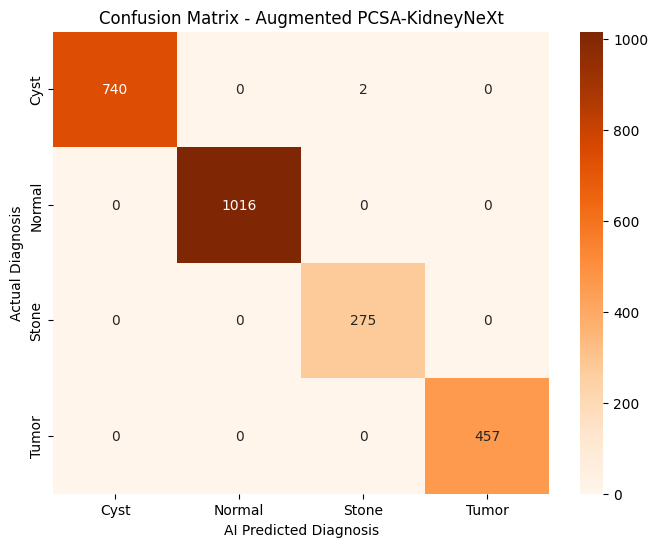

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Ensure the model is evaluating
model.eval()

all_preds = []
all_labels = []

print("🧪 Running final evaluation on the unseen Test Set for AUGMENTED model...")

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

print("\n📊 --- Final Augmented Classification Report ---")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Augmented PCSA-KidneyNeXt')
plt.ylabel('Actual Diagnosis')
plt.xlabel('AI Predicted Diagnosis')
plt.show()

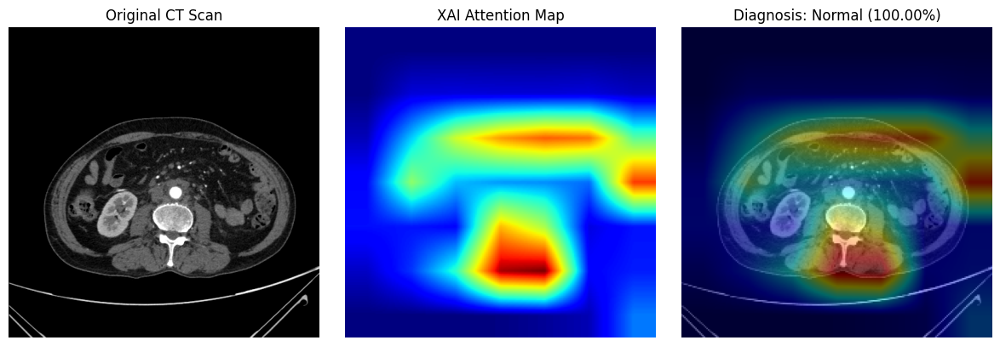

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from PIL import Image

# 1. --- The Grad-CAM Class ---
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None

        # Hooks to capture gradients and activations
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, class_idx):
        # Forward pass
        output = self.model(input_tensor)
        self.model.zero_grad()

        # Target specific class for explanation
        loss = output[0, class_idx]
        loss.backward()

        # Weight the channels by the gradients
        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]
        weights = np.mean(gradients, axis=(1, 2))

        # Build the heatmap
        heatmap = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            heatmap += w * activations[i, :, :]

        # ReLU on heatmap (we only care about positive influences)
        heatmap = np.maximum(heatmap, 0)

        # Normalize between 0 and 1
        heatmap /= np.max(heatmap) if np.max(heatmap) != 0 else 1
        return heatmap

# 2. --- Visualization Function ---
def visualize_xai(model, image_path, class_names, target_layer):
    # Load and preprocess image
    original_img = Image.open(image_path).convert('RGB')
    input_tensor = data_transforms(original_img).unsqueeze(0).to(device)

    # Get Prediction
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        prob = F.softmax(output, dim=1)
        conf, pred_idx = torch.max(prob, 1)
        pred_idx = pred_idx.item()

    # Generate Heatmap
    cam = GradCAM(model, target_layer)
    heatmap = cam.generate_heatmap(input_tensor, pred_idx)

    # Process for overlay
    img_cv = cv2.cvtColor(np.array(original_img), cv2.COLOR_RGB2BGR)
    img_cv = cv2.resize(img_cv, (224, 224))

    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)

    # Superimpose the heatmap on original image
    overlay = cv2.addWeighted(img_cv, 0.6, heatmap_colored, 0.4, 0)

    # Plotting
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.title(f"Original CT Scan")
    plt.imshow(original_img)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title(f"XAI Attention Map")
    plt.imshow(heatmap_resized, cmap='jet')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title(f"Diagnosis: {class_names[pred_idx]} ({conf.item()*100:.2f}%)")
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# 3. --- Execute on a sample from the Test Set ---
# Target the very last block of your custom model
target_layer = model.stage4
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# Pick a random sample from the test dataframe
sample_path = test_df.sample(1)['path'].values[0]
visualize_xai(model, sample_path, class_names, target_layer)


✨ Generating XAI Report for Cyst...


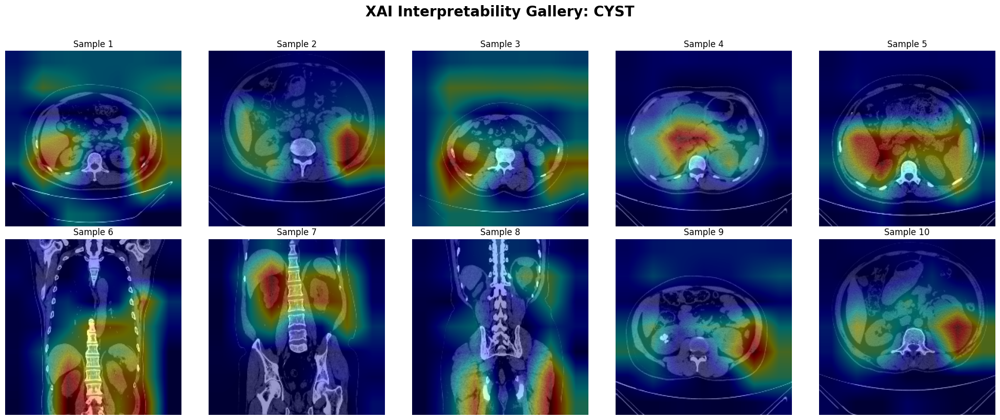


✨ Generating XAI Report for Normal...


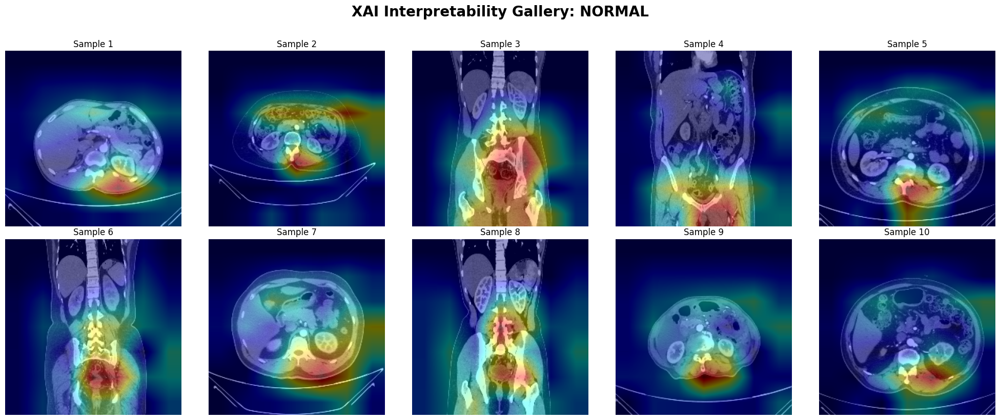


✨ Generating XAI Report for Stone...


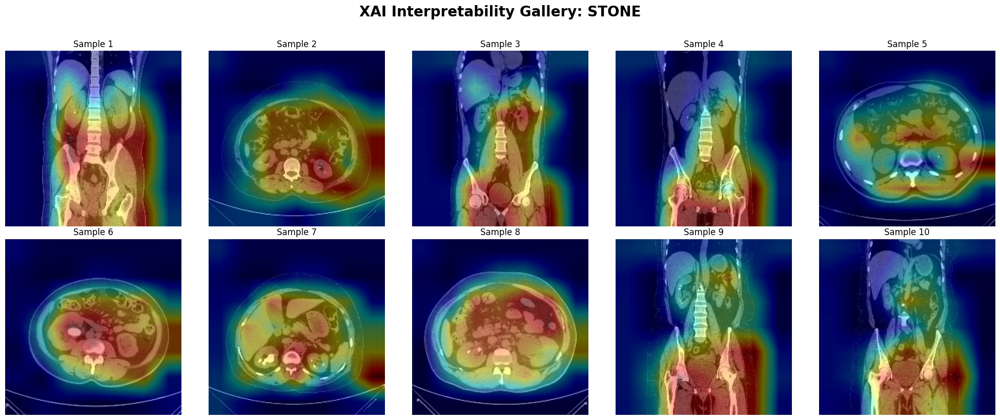


✨ Generating XAI Report for Tumor...


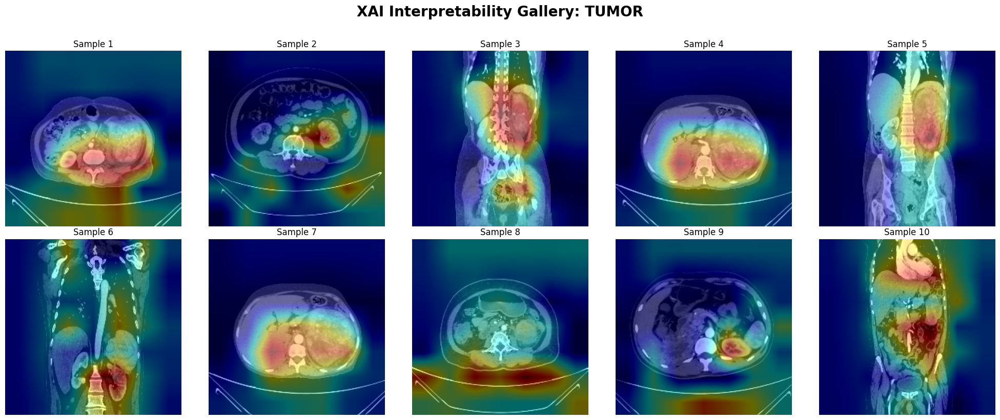

In [ ]:
import os
import random

def generate_class_gallery(model, dataframe, target_class_idx, class_name, target_layer, num_samples=10):
    # Filter the test dataframe for the specific class
    class_df = dataframe[dataframe['target'] == target_class_idx]

    # Select random samples
    samples = class_df.sample(num_samples)['path'].values

    # Set up the plotting grid
    cols = 5
    rows = 2
    plt.figure(figsize=(20, 8))
    plt.suptitle(f"XAI Interpretability Gallery: {class_name.upper()}", fontsize=20, fontweight='bold', y=1.02)

    cam = GradCAM(model, target_layer)

    for i, img_path in enumerate(samples):
        # Preprocess
        original_img = Image.open(img_path).convert('RGB')
        input_tensor = data_transforms(original_img).unsqueeze(0).to(device)

        # Get Heatmap
        heatmap = cam.generate_heatmap(input_tensor, target_class_idx)

        # Superimpose
        img_cv = cv2.cvtColor(np.array(original_img), cv2.COLOR_RGB2BGR)
        img_cv = cv2.resize(img_cv, (224, 224))
        heatmap_resized = cv2.resize(heatmap, (224, 224))
        heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        overlay = cv2.addWeighted(img_cv, 0.6, heatmap_colored, 0.4, 0)

        # Plot
        plt.subplot(rows, cols, i + 1)
        plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        plt.title(f"Sample {i+1}", fontsize=12)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

# --- Run the Gallery Generation ---
target_layer = model.stage4
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

for idx, name in enumerate(class_names):
    print(f"\n✨ Generating XAI Report for {name}...")
    generate_class_gallery(model, test_df, idx, name, target_layer, num_samples=10)

In [ ]:
#2nd phase

**instance segmentation of the tumor **

In [ ]:
!pip install -q "ultralytics<=8.3.40" roboflow supervision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 898.5/898.5 kB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.0/94.0 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.4/217.4 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 75.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 98.6 MB/s eta 0:00:00


In [ ]:
# 1. Install necessary libraries (YOLO, Roboflow, and Supervision for visualization)
!pip install -q "ultralytics<=8.3.40" roboflow supervision

# 2. Set up the working directory
import os
os.makedirs('/content/datasets', exist_ok=True)
%cd /content/datasets

# 3. Download the Roboflow Dataset
from roboflow import Roboflow
rf = Roboflow(api_key="LYQUKUSB3DcOCIa4VAIW")
project = rf.workspace("capstone-6ikwu").project("kidney-tumor-uqpis-ytprj")
version = project.version(1)
dataset = version.download("yolov11")

# 4. Train the YOLOv11 Segmentation Model
from ultralytics import YOLO

print("🔄 Initializing YOLOv11 Segmentation Model...")
# Load the pre-trained YOLOv11 Nano Segmentation model (fastest for Colab)
model = YOLO("yolo11n-seg.pt")

print("🚀 Starting Training...")
# Start training!
results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=50,             # 50 epochs is a great starting point for segmentation
    imgsz=640,             # Matches the 640x640 preprocessing you did in Roboflow
    device=0,              # Uses the Colab T4 GPU
    project="/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation", # Saves to your Drive
    name="tumor_segmentation_v1"
)

/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Kidney-Tumor-1 in yolov11:: 100%|██████████| 4535/4535 [00:00<00:00, 5245.86it/s]


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🔄 Initializing YOLOv11 Segmentation Model...


100%|██████████| 5.90M/5.90M [00:00<00:00, 77.0MB/s]


🚀 Starting Training...
New https://pypi.org/project/ultralytics/8.4.14 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=segment, mode=train, model=yolo11n-seg.pt, data=/content/datasets/Kidney-Tumor-1/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation, name=tumor_segmentation_v1, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visua

100%|██████████| 755k/755k [00:00<00:00, 29.3MB/s]


... (159 outputs left out)

                   all        338        745      0.913      0.874      0.957      0.778       0.92       0.88      0.958      0.748



50 epochs completed in 0.533 hours.
Optimizer stripped from /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/last.pt, 6.0MB
Optimizer stripped from /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt, 6.0MB

Validating /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt...
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 265 layers, 2,834,958 parameters, 0 gradients, 9.6 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 11/11 [00:06<00:00,  1.66it/s]


                   all        338        745      0.915      0.872      0.957      0.776      0.913      0.882      0.957       0.75
                kidney        235        328      0.934      0.915       0.97      0.815      0.935      0.925      0.972      0.761
                 tumor        338        417      0.897       0.83      0.944      0.738      0.891      0.839      0.942      0.739
Speed: 0.3ms preprocess, 3.9ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1


In [ ]:
# 1. Install necessary libraries (YOLO, Roboflow, and Supervision for visualization)
!pip install -q "ultralytics<=8.3.40" roboflow supervision

# 2. Set up the working directory
import os
os.makedirs('/content/datasets', exist_ok=True)
%cd /content/datasets

# 3. Download the Roboflow Dataset
from roboflow import Roboflow
rf = Roboflow(api_key="LYQUKUSB3DcOCIa4VAIW")
project = rf.workspace("capstone-6ikwu").project("kidney-tumor-uqpis-ytprj")
version = project.version(1)
dataset = version.download("yolov11")

/content/datasets
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Kidney-Tumor-1 in yolov11:: 100%|██████████| 4535/4535 [00:00<00:00, 7307.69it/s]


🧠 Loading the Surgical Planner (YOLOv11) weights...
🔍 Running inference on unseen scan...

image 1/1 /content/datasets/Kidney-Tumor-1/test/images/Tumor-1484-_jpg.rf.0400d65a6c1594cc68908887abc94132.jpg: 640x640 1 tumor, 32.4ms
Speed: 3.9ms preprocess, 32.4ms inference, 7.3ms postprocess per image at shape (1, 3, 640, 640)
Results saved to runs/segment/predict
✅ Segmentation Complete:


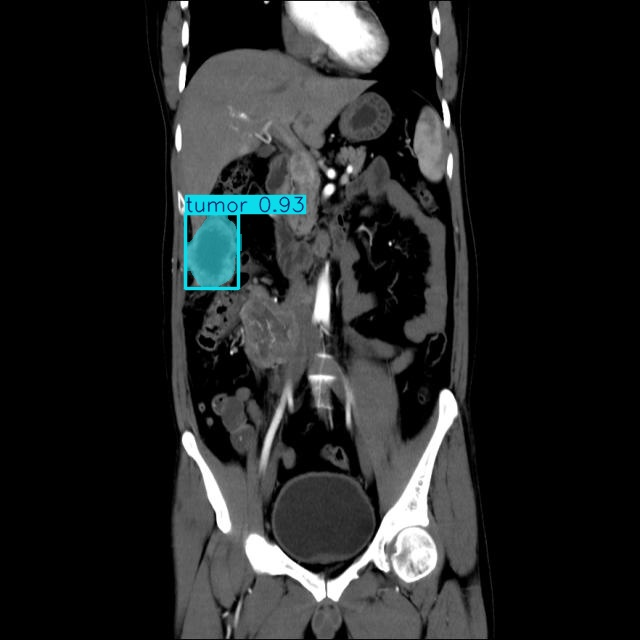

In [ ]:
import glob
from IPython.display import Image, display
from ultralytics import YOLO

print("🧠 Loading the Surgical Planner (YOLOv11) weights...")
# Load the best weights from your Drive
model = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")

# Grab a random image from the test set
test_images = glob.glob('/content/datasets/Kidney-Tumor-1/test/images/*.jpg')
sample_image = test_images[2] # Picking the 3rd image in the list

print(f"🔍 Running inference on unseen scan...")
# Run the prediction (conf=0.5 means it only draws masks it is 50%+ confident in)
results = model.predict(source=sample_image, conf=0.5, save=True)

# Find where YOLO saved the output image and display it
result_dir = results[0].save_dir
img_name = sample_image.split('/')[-1]

print("✅ Segmentation Complete:")
display(Image(filename=f"{result_dir}/{img_name}"))

🧠 Loading the Surgical Planner (YOLOv11) weights...
🔍 Running batch inference on 12 unseen scans...

0: 640x640 2 kidneys, 15.6ms
1: 640x640 2 kidneys, 1 tumor, 15.6ms
2: 640x640 1 tumor, 15.6ms
3: 640x640 1 tumor, 15.6ms
4: 640x640 1 tumor, 15.6ms
5: 640x640 1 kidney, 1 tumor, 15.6ms
6: 640x640 1 kidney, 1 tumor, 15.6ms
7: 640x640 1 kidney, 1 tumor, 15.6ms
8: 640x640 1 kidney, 1 tumor, 15.6ms
9: 640x640 2 kidneys, 1 tumor, 15.6ms
10: 640x640 1 tumor, 15.6ms
11: 640x640 2 kidneys, 1 tumor, 15.6ms
Speed: 8.7ms preprocess, 15.6ms inference, 7.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to YOLO_Predictions/Batch_Test


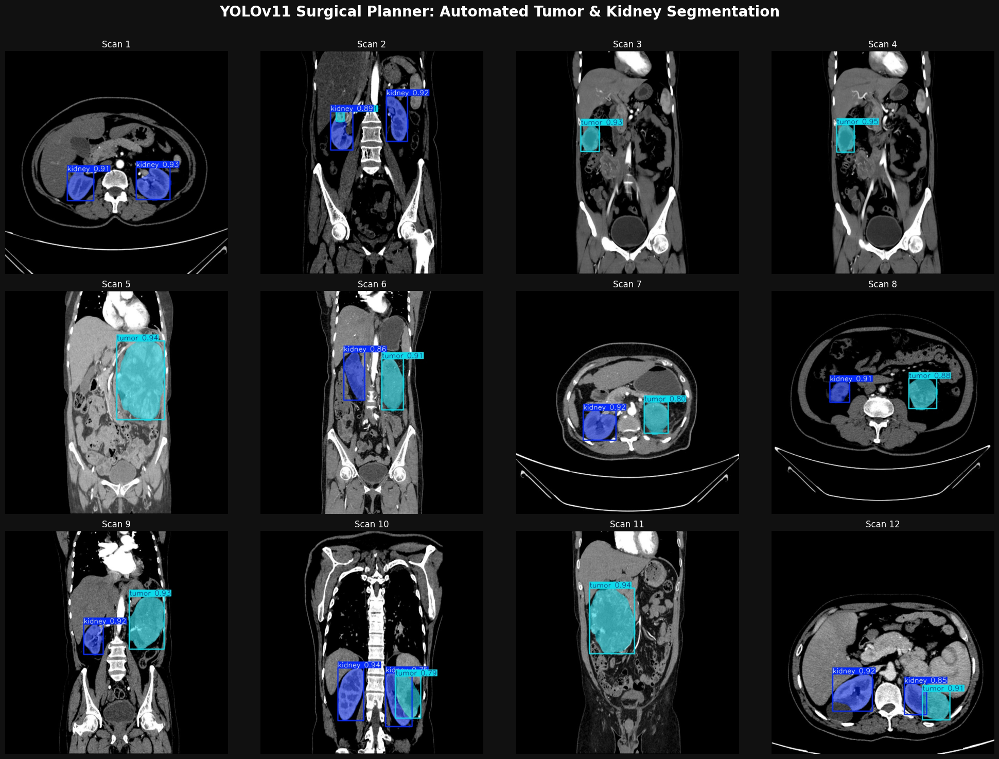

In [ ]:
import glob
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO

print("🧠 Loading the Surgical Planner (YOLOv11) weights...")
# Load the best weights from your Drive
model = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")

# Grab the first 12 images from the test set
test_images = glob.glob('/content/datasets/Kidney-Tumor-1/test/images/*.jpg')
sample_images = test_images[:12]

print(f"🔍 Running batch inference on 12 unseen scans...")
# YOLO can process a list of images all at once!
results = model.predict(source=sample_images, conf=0.5, save=True, project="YOLO_Predictions", name="Batch_Test")

# Get the directory where YOLO saved the drawn masks
result_dir = results[0].save_dir

# ---------------------------------------------------------
# Displaying the results in a professional clinical grid
# ---------------------------------------------------------
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle("YOLOv11 Surgical Planner: Automated Tumor & Kidney Segmentation", fontsize=20, weight='bold', color='white')
fig.patch.set_facecolor('#111111') # Dark theme for medical imaging

for i, ax in enumerate(axes.flat):
    if i < len(sample_images):
        # Extract filename and locate the saved prediction
        img_name = sample_images[i].split('/')[-1]
        img_path = f"{result_dir}/{img_name}"

        # OpenCV loads images in BGR format, convert to RGB for Matplotlib
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)

        ax.set_title(f"Scan {i+1}", color='white')
        ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

In [ ]:
import os

folder_path = '/content/drive/MyDrive/Capstone_Kidney_Project/'

if os.path.exists(folder_path):
    print(f"📂 Looking inside: {folder_path}\n")
    files = os.listdir(folder_path)
    for file in files:
        if file.endswith('.pth'):
            print(f"✅ FOUND WEIGHTS: {file}")
        else:
            print(f"   - {file}")
else:
    print("❌ Folder not found! Check your Google Drive to see if the folder is named differently.")

📂 Looking inside: /content/drive/MyDrive/Capstone_Kidney_Project/

   - YOLO_Segmentation


In [ ]:
import shutil
import os
from google.colab import drive

# 1. Rescue the YOLO weights from the "fake" local drive
fake_yolo_path = '/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation'
safe_backup_path = '/content/YOLO_Backup'

if os.path.exists(fake_yolo_path):
    print("🛟 Rescuing YOLO weights from local storage...")
    shutil.copytree(fake_yolo_path, safe_backup_path, dirs_exist_ok=True)
    print("✅ YOLO weights safely backed up!")

# 2. Delete the "fake" drive folder so Colab can mount the real one
print("🧹 Cleaning up the blocked mount point...")
!rm -rf /content/drive

# 3. Mount the REAL Google Drive
print("🔗 Mounting your real Google Drive. (Please accept the prompt!)...")
drive.mount('/content/drive')

# 4. Copy the YOLO weights into the real Drive so they are saved forever
real_project_path = '/content/drive/MyDrive/Capstone_Kidney_Project'
real_yolo_path = '/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation'

if os.path.exists(safe_backup_path) and os.path.exists(real_project_path):
    print("📂 Moving YOLO weights into your real Google Drive...")
    shutil.copytree(safe_backup_path, real_yolo_path, dirs_exist_ok=True)
    print("✅ YOLO weights are now permanently saved!")

# 5. Verify Colab can finally see your classification weights!
pth_file = '/content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_60epochs_AUGMENTED.pth'
if os.path.exists(pth_file):
    print("\n🎉 SUCCESS! Colab can finally see your PCSA-KidneyNeXt weights!")
else:
    print("\n❌ Still can't see the weights. Let me know if this happens.")

🛟 Rescuing YOLO weights from local storage...
✅ YOLO weights safely backed up!
🧹 Cleaning up the blocked mount point...
🔗 Mounting your real Google Drive. (Please accept the prompt!)...
Mounted at /content/drive
📂 Moving YOLO weights into your real Google Drive...
✅ YOLO weights are now permanently saved!

🎉 SUCCESS! Colab can finally see your PCSA-KidneyNeXt weights!


🧠 Loading PCSA-KidneyNeXt Weights...
🔍 Running Zero-Shot External Validation...


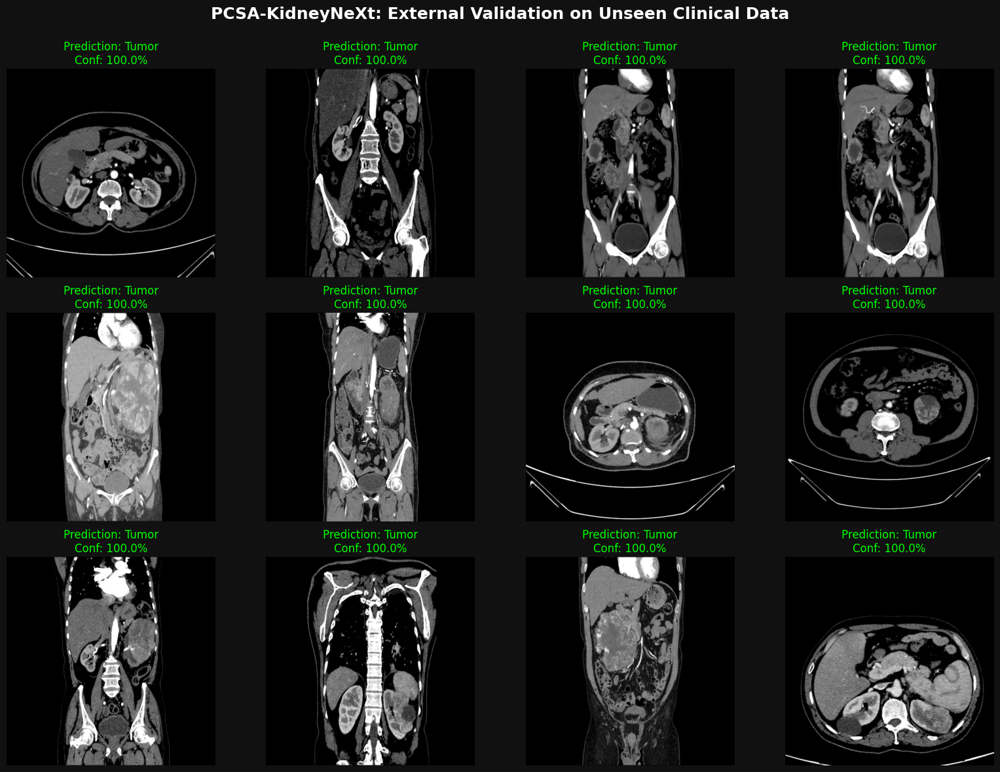

In [ ]:
import torch
from torchvision import transforms
from PIL import Image
import glob
import matplotlib.pyplot as plt

# 1. Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Load your custom PCSA-KidneyNeXt architecture
# (Assuming the 'model' object is already instantiated in your notebook from earlier)
print("🧠 Loading PCSA-KidneyNeXt Weights...")
model.load_state_dict(torch.load('/content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_60epochs_AUGMENTED.pth', map_location=device))
model.eval()
model.to(device)

# 3. Standard classification preprocessing (Matches your original training pipeline)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Define the 4 classes your model was trained on
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# 4. Grab a batch of unseen images from the Roboflow dataset
external_images = glob.glob('/content/datasets/Kidney-Tumor-1/test/images/*.jpg')[:12]

print("🔍 Running Zero-Shot External Validation...")

# 5. Display the predictions in a clinical grid
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle("PCSA-KidneyNeXt: External Validation on Unseen Clinical Data", fontsize=18, weight='bold', color='white')
fig.patch.set_facecolor('#111111') # Dark medical theme

with torch.no_grad():
    for i, ax in enumerate(axes.flat):
        if i < len(external_images):
            img_path = external_images[i]
            img = Image.open(img_path).convert('RGB')

            # Prepare tensor and predict
            input_tensor = transform(img).unsqueeze(0).to(device)
            outputs = model(input_tensor)

            # Get the highest confidence class
            probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
            confidence, predicted_idx = torch.max(probabilities, 0)
            pred_class = class_names[predicted_idx.item()]

            # Plotting
            ax.imshow(img)
            # Highlight Tumor predictions in bright green, others in blue
            title_color = '#00ff00' if pred_class == 'Tumor' else '#00ccff'
            ax.set_title(f"Prediction: {pred_class}\nConf: {confidence.item()*100:.1f}%", color=title_color)
            ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()

🧠 Initializing the Two-Stage Clinical Pipeline...

🏥 Analyzing Scan: Tumor-1999-_jpg.rf.13b1e95f12e21ae5007af8a3d8908f7b.jpg
----------------------------------------
➡️ Stage 1 Diagnosis: Tumor (Confidence: 100.00%)
⚠️ Severe pathology detected. Routing to Stage 2: Surgical Planner...


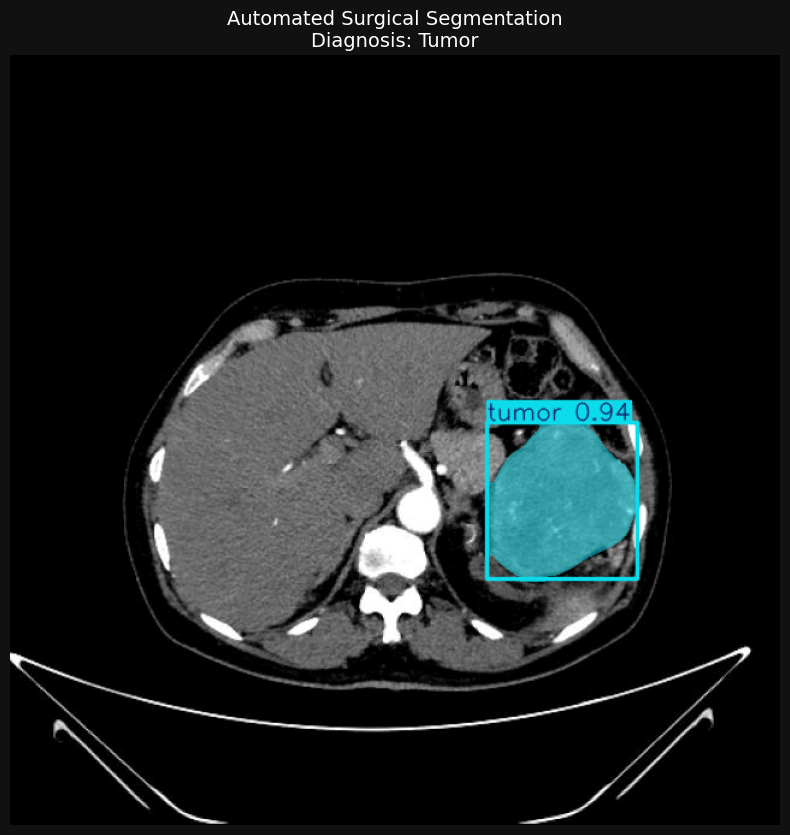

In [ ]:
import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
import glob
import random

print("🧠 Initializing the Two-Stage Clinical Pipeline...")

# 1. Prepare Stage 1: The Diagnostician (PCSA-KidneyNeXt)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier_model = model # This is your currently loaded 2.11M parameter model
classifier_model.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# 2. Prepare Stage 2: The Surgical Planner (YOLOv11)
segmenter_model = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")

# 3. The Master Pipeline Function
def run_clinical_pipeline(image_path):
    print(f"\n🏥 Analyzing Scan: {image_path.split('/')[-1]}")
    print("-" * 40)

    # --- STAGE 1: Fast Classification ---
    img = Image.open(image_path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = classifier_model(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # --- STAGE 2: Conditional YOLO Routing ---
    if diagnosis == "Tumor":
        print("⚠️ Severe pathology detected. Routing to Stage 2: Surgical Planner...")

        # Run YOLO inference
        results = segmenter_model.predict(source=image_path, conf=0.5, save=False, verbose=False)

        # Display the output with drawn surgical margins
        annotated_img = results[0].plot()
        plt.figure(figsize=(10, 10))
        plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
        plt.title(f"Automated Surgical Segmentation\nDiagnosis: {diagnosis}", color='white', fontsize=14)
        plt.axis('off')

        # Dark clinical theme
        plt.gcf().patch.set_facecolor('#111111')
        plt.show()

    else:
        print("✅ No tumor detected. Patient cleared from surgical pipeline.")
        plt.figure(figsize=(6, 6))
        plt.imshow(img)
        plt.title(f"Cleared: {diagnosis}", color='#00ccff', fontsize=14)
        plt.axis('off')
        plt.gcf().patch.set_facecolor('#111111')
        plt.show()

# 4. Test it on a random image from the Roboflow dataset!
test_images = glob.glob('/content/datasets/Kidney-Tumor-1/test/images/*.jpg')
random_scan = random.choice(test_images)

run_clinical_pipeline(random_scan)

cyst segmentation

stop the code because v1(model weights ) is already present in the the g drive just we need to unzip the dataset for this  code is ->  
 # --- JUST DOWNLOAD THE DATASET (NO TRAINING) ---
!pip install -q "ultralytics<=8.3.40" roboflow supervision

import os
os.makedirs('/content/datasets', exist_ok=True)
%cd /content/datasets

print("📥 Downloading Roboflow Images...")
from roboflow import Roboflow
rf = Roboflow(api_key="LYQUKUSB3DcOCIa4VAIW")
project = rf.workspace("capstone-6ikwu").project("kidney-cyst-6ytvf-w7ogs")
version = project.version(1)
dataset = version.download("yolov11")

print("✅ Images downloaded successfully to temporary memory! Ready for testing.")

In [ ]:


# checking the weights present or not

import os
from google.colab import drive

# 1. Mount Drive just in case it isn't connected yet
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Define the exact path to your saved Cyst model
cyst_model_path = "/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt"

# 3. Check if the file exists
print("🔍 Searching Google Drive for your trained weights...")
print("-" * 50)

if os.path.exists(cyst_model_path):
    print(f"🎉 SUCCESS! Your trained Cyst model is safely stored at:\n{cyst_model_path}")
    print("\n➡️ You DO NOT need to retrain! You can skip the training block completely.")
else:
    print(f"⚠️ NOT FOUND: Could not find the file at:\n{cyst_model_path}")
    print("\n➡️ This means it was either saved somewhere else, or the training didn't finish. You will need to run the training block again.")

🔍 Searching Google Drive for your trained weights...
--------------------------------------------------
🎉 SUCCESS! Your trained Cyst model is safely stored at:
/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt

➡️ You DO NOT need to retrain! You can skip the training block completely.


In [ ]:
# --- JUST DOWNLOAD THE DATASET (NO TRAINING) ---
!pip install -q "ultralytics<=8.3.40" roboflow supervision

import os
os.makedirs('/content/datasets', exist_ok=True)
%cd /content/datasets

print("📥 Downloading Roboflow Images...")
from roboflow import Roboflow
rf = Roboflow(api_key="LYQUKUSB3DcOCIa4VAIW")
project = rf.workspace("capstone-6ikwu").project("kidney-cyst-6ytvf-w7ogs")
version = project.version(1)
dataset = version.download("yolov11")

print("✅ Images downloaded successfully to temporary memory! Ready for testing.")

/content/datasets
📥 Downloading Roboflow Images...
loading Roboflow workspace...
loading Roboflow project...
✅ Images downloaded successfully to temporary memory! Ready for testing.


🧠 Loading the Cyst Specialist (YOLOv11) weights...
🔍 Running batch inference on 12 unseen cyst scans...

0: 640x640 1 cyst, 9.2ms
1: 640x640 2 kidneys, 9.2ms
2: 640x640 1 cyst, 1 kidney, 9.2ms
3: 640x640 2 cysts, 2 kidneys, 9.2ms
4: 640x640 1 cyst, 2 kidneys, 9.2ms
5: 640x640 1 cyst, 2 kidneys, 9.2ms
6: 640x640 1 cyst, 2 kidneys, 9.2ms
7: 640x640 2 cysts, 2 kidneys, 9.2ms
8: 640x640 1 cyst, 1 kidney, 9.2ms
9: 640x640 1 cyst, 2 kidneys, 9.2ms
10: 640x640 1 cyst, 2 kidneys, 9.2ms
11: 640x640 3 cysts, 1 kidney, 9.2ms
Speed: 2.1ms preprocess, 9.2ms inference, 3.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to YOLO_Predictions/Cyst_Batch_Test


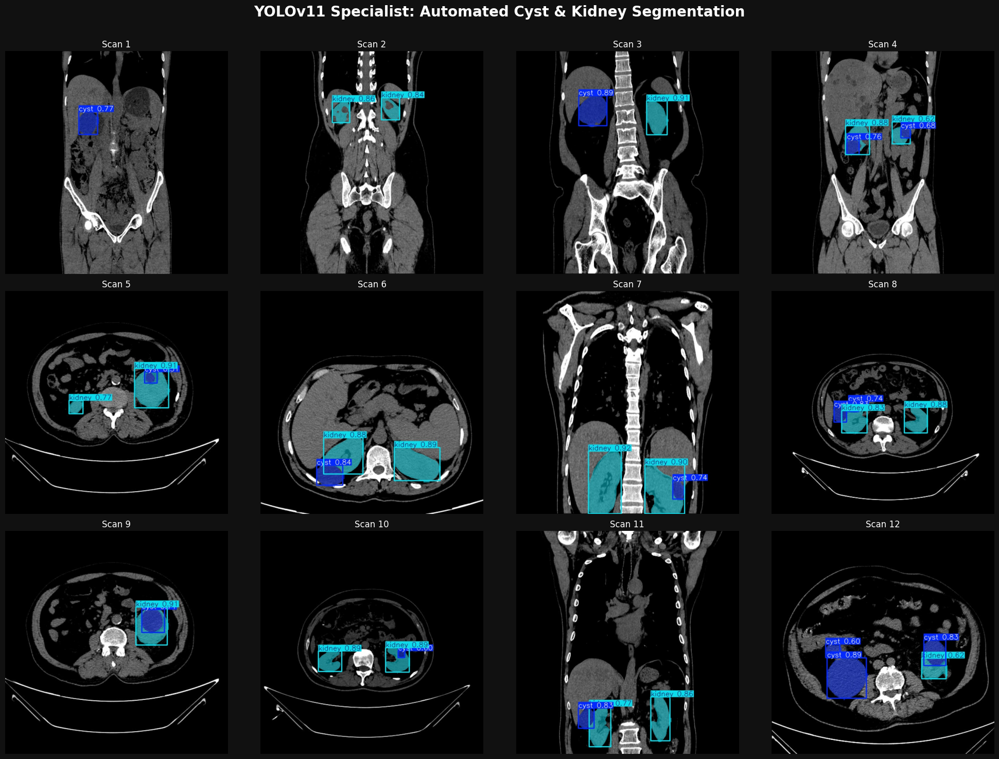

In [ ]:
import glob
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO

print("🧠 Loading the Cyst Specialist (YOLOv11) weights...")
# Load the best weights from your newly trained cyst model
model = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# Grab the first 12 images from the cyst test set
# (Using a wildcard *yst* to ensure Colab finds the correct extracted folder name)
test_images = glob.glob('/content/datasets/*yst*/test/images/*.jpg')
sample_images = test_images[:12]

print(f"🔍 Running batch inference on 12 unseen cyst scans...")
# Process the list of images all at once
results = model.predict(source=sample_images, conf=0.5, save=True, project="YOLO_Predictions", name="Cyst_Batch_Test")

# Get the directory where YOLO saved the drawn masks
result_dir = results[0].save_dir

# ---------------------------------------------------------
# Displaying the results in a professional clinical grid
# ---------------------------------------------------------
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
fig.suptitle("YOLOv11 Specialist: Automated Cyst & Kidney Segmentation", fontsize=20, weight='bold', color='white')
fig.patch.set_facecolor('#111111') # Dark theme for medical imaging

for i, ax in enumerate(axes.flat):
    if i < len(sample_images):
        # Extract filename and locate the saved prediction
        img_name = sample_images[i].split('/')[-1]
        img_path = f"{result_dir}/{img_name}"

        # OpenCV loads images in BGR format, convert to RGB for Matplotlib
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img)

        ax.set_title(f"Scan {i+1}", color='white')
        ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


🧠 Loading PCSA-KidneyNeXt Weights...
🔍 Running Zero-Shot External Validation on Cyst Data...


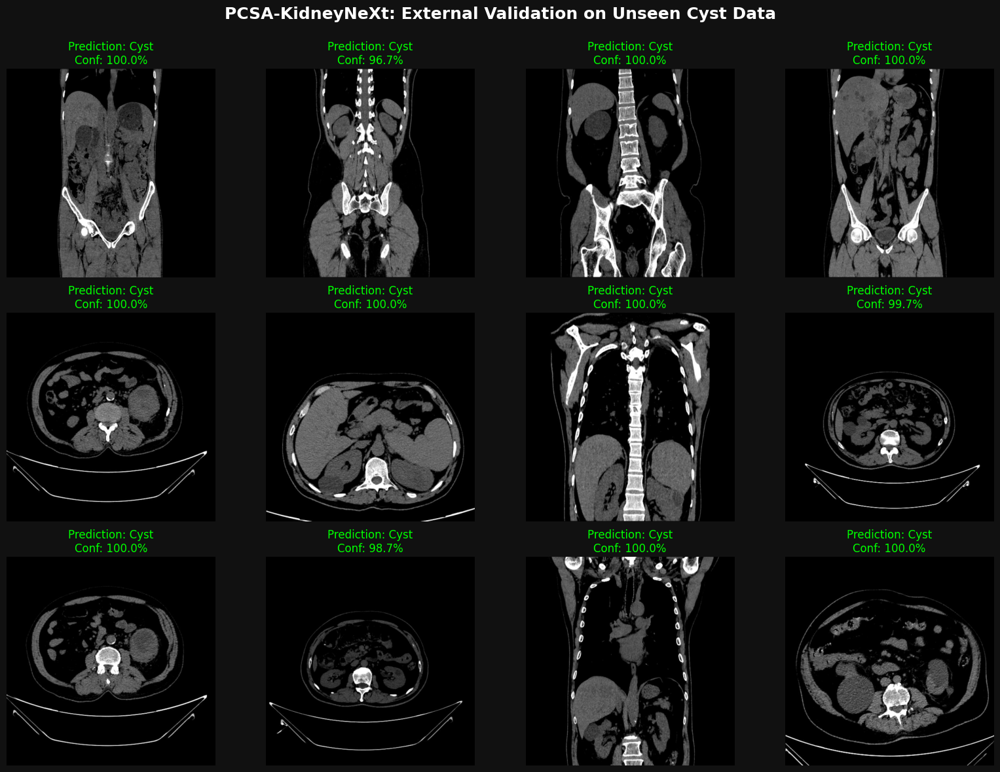

In [ ]:
import torch
from torchvision import transforms
from PIL import Image
import glob
import matplotlib.pyplot as plt

# 1. Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 🛑 2. Initialize your PyTorch Architecture here with the correct class name!
pcsa_classifier = PCSA_KidneyNeXt(num_classes=4)

print("🧠 Loading PCSA-KidneyNeXt Weights...")
pcsa_classifier.load_state_dict(torch.load('/content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_60epochs_AUGMENTED.pth', map_location=device))
pcsa_classifier.eval()
pcsa_classifier.to(device)

# 3. Standard classification preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# 4. Grab a batch of unseen images from the new CYST dataset
cyst_external_images = glob.glob('/content/datasets/*yst*/test/images/*.jpg')[:12]

print("🔍 Running Zero-Shot External Validation on Cyst Data...")

# 5. Display the predictions in a clinical grid
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
fig.suptitle("PCSA-KidneyNeXt: External Validation on Unseen Cyst Data", fontsize=18, weight='bold', color='white')
fig.patch.set_facecolor('#111111')

with torch.no_grad():
    for i, ax in enumerate(axes.flat):
        if i < len(cyst_external_images):
            img_path = cyst_external_images[i]
            img = Image.open(img_path).convert('RGB')

            # Prepare tensor and predict using the UNIQUE variable name
            input_tensor = transform(img).unsqueeze(0).to(device)
            outputs = pcsa_classifier(input_tensor)

            # Get the highest confidence class
            probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
            confidence, predicted_idx = torch.max(probabilities, 0)
            pred_class = class_names[predicted_idx.item()]

            # Plotting
            ax.imshow(img)
            # Highlight Cyst predictions in bright green, mistakes in red
            title_color = '#00ff00' if pred_class == 'Cyst' else '#ff3333'
            ax.set_title(f"Prediction: {pred_class}\nConf: {confidence.item()*100:.1f}%", color=title_color)
            ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()

🧠 Initializing the Ultimate Multi-Pathology Clinical Pipeline...
🔪 Loading Tumor Specialist...
💧 Loading Cyst Specialist...

🏥 Analyzing Scan: Cyst-3323-_jpg.rf.80541ba0675e54209be8f690e70d8bdb.jpg
--------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 99.72%)
💧 Fluid-filled sac detected. Routing to Cyst Surgical Planner...


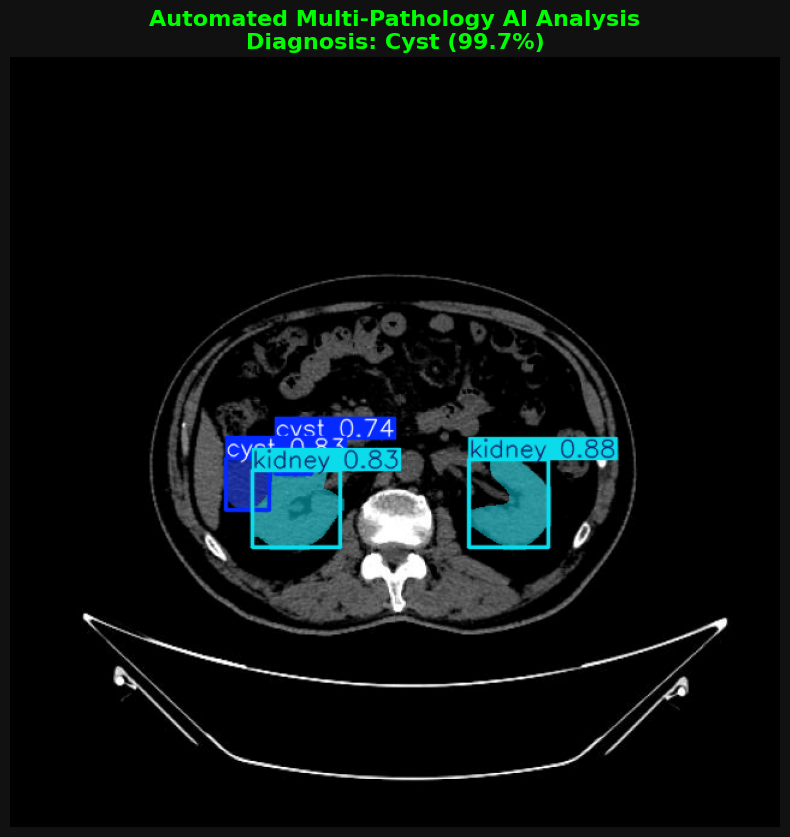

In [ ]:
import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
import glob
import random

print("🧠 Initializing the Ultimate Multi-Pathology Clinical Pipeline...")

# --- 1. Load Stage 1: The Diagnostician (PCSA-KidneyNeXt) ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# We use the pcsa_classifier you already initialized in the previous cell!
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# --- 2. Load Stage 2: The Surgical Specialists (YOLOv11) ---
print("🔪 Loading Tumor Specialist...")
tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")

print("💧 Loading Cyst Specialist...")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. The Master Pipeline Function ---
def master_clinical_pipeline(image_path):
    print(f"\n🏥 Analyzing Scan: {image_path.split('/')[-1]}")
    print("-" * 50)

    # --- STAGE 1: Fast Classification ---
    img = Image.open(image_path).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # --- STAGE 2: Conditional Specialist Routing ---
    plt.figure(figsize=(10, 10))

    if diagnosis == "Tumor":
        print("⚠️ Solid mass detected. Routing to Tumor Surgical Planner...")
        results = tumor_segmenter.predict(source=image_path, conf=0.5, save=False, verbose=False)
        annotated_img = results[0].plot()
        plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
        title_color = '#ff3333' # Red for Tumor

    elif diagnosis == "Cyst":
        print("💧 Fluid-filled sac detected. Routing to Cyst Surgical Planner...")
        results = cyst_segmenter.predict(source=image_path, conf=0.5, save=False, verbose=False)
        annotated_img = results[0].plot()
        plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
        title_color = '#00ff00' # Green for Cyst

    else:
        print(f"✅ Diagnosis is {diagnosis}. No surgical segmentation required.")
        plt.imshow(img)
        title_color = '#00ccff' # Blue for Normal/Stone

    # Formatting the final clinical output
    plt.title(f"Automated Multi-Pathology AI Analysis\nDiagnosis: {diagnosis} ({confidence.item()*100:.1f}%)", color=title_color, fontsize=16, weight='bold')
    plt.axis('off')
    plt.gcf().patch.set_facecolor('#111111')
    plt.show()

# --- 4. Test it dynamically! ---
# Combine test images from both datasets
tumor_images = glob.glob('/content/datasets/Kidney-Tumor-1/test/images/*.jpg')
cyst_images = glob.glob('/content/datasets/*yst*/test/images/*.jpg')
all_test_images = tumor_images + cyst_images

random_scan = random.choice(all_test_images)
master_clinical_pipeline(random_scan)

In [ ]:
import torch
import plotly.graph_objects as go
from ultralytics import YOLO
import glob
import random
import numpy as np

print("📐 Initializing 3D Coordinate Extraction...")

# 1. Load BOTH Specialist Models from your permanent Google Drive
tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# 2. Find ANY available test images in Colab's temporary storage using a wildcard
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')

if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty. Scroll up and run your Roboflow download cell again!")
else:
    sample_scan = random.choice(available_images)
    print(f"✅ Image found: {sample_scan.split('/')[-1]}")

    # 3. Run both segmenters (save=False because we only want the mathematical coordinates)
    tumor_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
    cyst_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)

    # 4. Set up our interactive 3D environment
    fig = go.Figure()
    found_pathology = False

    # 5. Helper function to extract polygons and push them into 3D space
    def add_masks_to_3d(results, color, z_offset):
        global found_pathology # <--- THE FIX: Changed from nonlocal to global

        if results[0].masks is not None:
            masks = results[0].masks.xy        # The raw [x, y] coordinates
            classes = results[0].boxes.cls     # The class ID
            class_names = results[0].names     # The names ('kidney', 'tumor', 'cyst')

            for i, mask in enumerate(masks):
                cls_id = int(classes[i].item())
                name = class_names[cls_id]

                x_coords = mask[:, 0]
                y_coords = mask[:, 1]

                # Push the pathology forward in the Z-axis to show volume
                if name in ['tumor', 'cyst']:
                    z_coords = np.ones_like(x_coords) * z_offset
                    plot_color = color
                    found_pathology = True
                else:
                    z_coords = np.zeros_like(x_coords)     # Keep normal kidney tissue at base level
                    plot_color = '#00ccff' # Blue

                # Draw the 3D polygon
                fig.add_trace(go.Scatter3d(
                    x=x_coords, y=y_coords, z=z_coords,
                    mode='lines+markers',
                    marker=dict(size=3, color=plot_color),
                    line=dict(color=plot_color, width=5),
                    name=f"Extracted {name.capitalize()} Boundary"
                ))

    # Apply the mathematical extraction
    add_masks_to_3d(tumor_results, '#ff3333', 5) # Red for Tumor, pushed +5 on Z-axis
    add_masks_to_3d(cyst_results, '#00ff00', 5)  # Green for Cyst, pushed +5 on Z-axis

    if not found_pathology:
        print("⚠️ Note: No tumor or cyst was detected in this specific scan. Try running the cell again for a different image!")

    # 6. Format the 3D workspace
    fig.update_layout(
        title="Interactive 3D Spatial Geometry Extraction",
        scene=dict(
            xaxis_title="X-Axis (Width)",
            yaxis_title="Y-Axis (Height)",
            zaxis_title="Z-Axis (Depth / Slice Index)",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333", showbackground=True),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333", showbackground=True),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", showbackground=True, range=[-10, 10]),
        ),
        paper_bgcolor="#111111",
        font=dict(color="white"),
        margin=dict(l=0, r=0, b=0, t=50)
    )

    print("✅ Geometry successfully extracted! Click and drag the plot below to rotate it in 3D space.")
    fig.show()

📐 Initializing 3D Coordinate Extraction...
✅ Image found: Cyst-3621-_jpg.rf.aa8b895fc9f17b0dda3415ca4bcdf5b9.jpg
✅ Geometry successfully extracted! Click and drag the plot below to rotate it in 3D space.


🧠 Initializing the Ultimate 2D-to-3D Clinical Pipeline...

🏥 Analyzing Scan: Cyst-2442-_jpg.rf.bf775ec56ef29dfebdecb04bcfcbb9f3.jpg
--------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 99.92%)


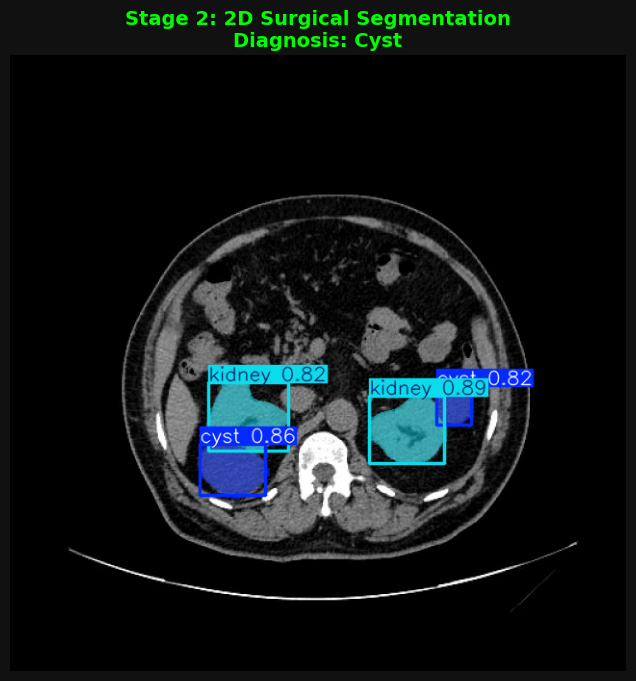


📐 Stage 3: Extracting 3D Spatial Geometry...
✅ 3D Geometry Extracted! Rotate the plot below:


In [ ]:
import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from ultralytics import YOLO
import glob
import random
import numpy as np

print("🧠 Initializing the Ultimate 2D-to-3D Clinical Pipeline...")

# --- 1. Ensure PCSA Classifier is ready ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# --- 2. Load YOLO Specialists ---
tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. Grab a random image ---
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')

if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🏥 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 50)

    # ==========================================
    # STAGE 1: PCSA CLASSIFICATION
    # ==========================================
    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # ==========================================
    # STAGE 2: 2D SURGICAL SEGMENTATION
    # ==========================================
    plt.figure(figsize=(8, 8))
    yolo_results = None
    z_offset = 0

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5 # Red
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        plt.imshow(cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB))
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5 # Green
    else:
        plt.imshow(img)
        title_color = '#00ccff' # Blue for Normal/Stone

    plt.title(f"Stage 2: 2D Surgical Segmentation\nDiagnosis: {diagnosis}", color=title_color, fontsize=14, weight='bold')
    plt.axis('off')
    plt.gcf().patch.set_facecolor('#111111')
    plt.show()

    # ==========================================
    # STAGE 3: 3D GEOMETRY EXTRACTION
    # ==========================================
    if yolo_results is not None and yolo_results[0].masks is not None:
        print("\n📐 Stage 3: Extracting 3D Spatial Geometry...")
        fig = go.Figure()

        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names

        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]

            x_coords = mask[:, 0]
            y_coords = mask[:, 1]

            # Push pathology forward, keep kidney flat
            if name in ['tumor', 'cyst']:
                z_coords = np.ones_like(x_coords) * z_offset
                c = plot_color
            else:
                z_coords = np.zeros_like(x_coords)
                c = '#00ccff' # Healthy kidney is blue

            fig.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color=c),
                line=dict(color=c, width=5),
                name=f"Extracted {name.capitalize()} Boundary"
            ))

        fig.update_layout(
            title=f"Stage 3: Interactive 3D Geometry ({diagnosis})",
            scene=dict(
                xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
                xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
            ),
            paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
        )
        print("✅ 3D Geometry Extracted! Rotate the plot below:")
        fig.show()

    elif diagnosis in ["Tumor", "Cyst"]:
        print("\n⚠️ Note: Model classified as pathology, but YOLO didn't find confident boundaries to extract in 3D.")
    else:
        print("\n✅ No pathology detected. 3D spatial extraction bypassed.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 51.4 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
🧠 Initializing the Ultimate Explainable 2D-to-3D Pipeline...

🏥 Analyzing Scan: Cyst-3298-_jpg.rf.c658fd4631d7b6675630476322c8e29a.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 99.90%)


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning:

adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)



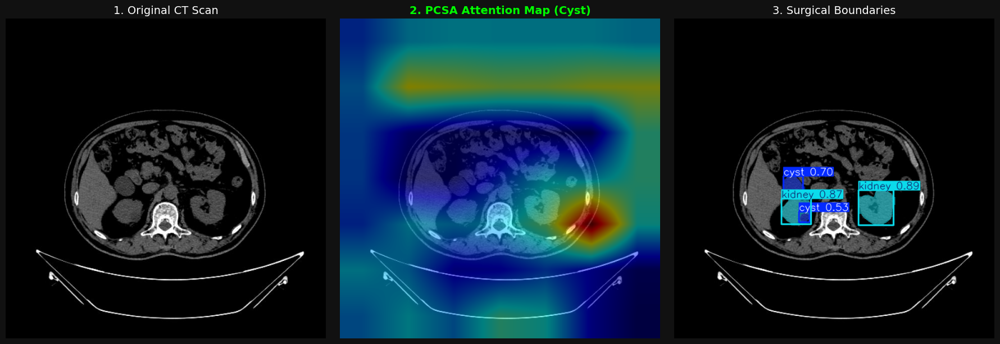


📐 Stage 3: Extracting 3D Spatial Geometry...
✅ 3D Geometry Extracted! Rotate the plot below:


In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from ultralytics import YOLO
import glob
import random
import numpy as np

# --- NEW GRAD-CAM IMPORTS ---
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🧠 Initializing the Ultimate Explainable 2D-to-3D Pipeline...")

# --- 1. Ensure PCSA Classifier is ready ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

# --- 2. Load YOLO Specialists ---
tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. Grab a random image ---
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')

if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🏥 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    # ==========================================
    # STAGE 1: PCSA CLASSIFICATION & GRAD-CAM
    # ==========================================
    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Generate Grad-CAM on the final layer (stage4) of your PCSA model
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]

    # We use unsqueeze to add the batch dimension back if needed by grad-cam
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

    # Resize the heatmap to map perfectly over the original high-res image
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # ==========================================
    # STAGE 2: 2D SURGICAL SEGMENTATION
    # ==========================================
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff' # Default Blue
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5 # Red
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5 # Green
    else:
        annotated_img = np.array(img) # No segmentation needed

    # --- Plotting the 1x3 Clinical Dashboard ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#111111')

    # Panel 1: Original
    axes[0].imshow(img)
    axes[0].set_title("1. Original CT Scan", color='white', fontsize=14)
    axes[0].axis('off')

    # Panel 2: Grad-CAM Explainability
    axes[1].imshow(cam_image)
    axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold')
    axes[1].axis('off')

    # Panel 3: YOLO Segmentation
    axes[2].imshow(annotated_img)
    axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14)
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    # ==========================================
    # STAGE 3: 3D GEOMETRY EXTRACTION
    # ==========================================
    if yolo_results is not None and yolo_results[0].masks is not None:
        print("\n📐 Stage 3: Extracting 3D Spatial Geometry...")
        fig_3d = go.Figure()

        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names

        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]

            x_coords = mask[:, 0]
            y_coords = mask[:, 1]

            if name in ['tumor', 'cyst']:
                z_coords = np.ones_like(x_coords) * z_offset
                c = plot_color
            else:
                z_coords = np.zeros_like(x_coords)
                c = '#00ccff'

            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color=c),
                line=dict(color=c, width=5),
                name=f"Extracted {name.capitalize()}"
            ))

        fig_3d.update_layout(
            title=f"Stage 3: Interactive 3D Geometry ({diagnosis})",
            scene=dict(
                xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
                xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
            ),
            paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
        )
        print("✅ 3D Geometry Extracted! Rotate the plot below:")
        fig_3d.show()

In [ ]:
# 1. Install the Hugging Face Transformers library
!pip install -q transformers

from transformers import pipeline

print("🏥 Initializing PubMedBERT Clinical NLP Engine...")

# 2. Load a PubMedBERT model specifically fine-tuned for Medical Named Entity Recognition (NER)
nlp_ner = pipeline(
    "ner",
    model="manpreetk/biomednlp-pubmedbert-base-uncased-abstract-fulltext-ndd-ner",
    aggregation_strategy="simple"
)

# 3. A sample of a messy, unstructured patient history
patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""

print("\n📋 Analyzing Patient Medical Notes...")
print("-" * 60)

# 4. Run the text through the NLP model
extracted_entities = nlp_ner(patient_notes)

# 5. Display the extracted clinical entities
for entity in extracted_entities:
    print(f"[{entity['entity_group'].upper()}] -> {entity['word']}")

print("-" * 60)
print("✅ NLP Analysis Complete!")

🏥 Initializing PubMedBERT Clinical NLP Engine...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning:


The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.



config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: manpreetk/biomednlp-pubmedbert-base-uncased-abstract-fulltext-ndd-ner
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]


📋 Analyzing Patient Medical Notes...
------------------------------------------------------------
------------------------------------------------------------
✅ NLP Analysis Complete!


In [ ]:
import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

print("🏥 Initializing the Complete AI Hospital Mainframe...")

# --- 1. Load the NLP Medical Scribe (PubMedBERT) ---
print("📚 Loading Medical NLP Engine...")
nlp_ner = pipeline(
    "ner",
    model="manpreetk/biomednlp-pubmedbert-base-uncased-abstract-fulltext-ndd-ner",
    aggregation_strategy="simple"
)

# A sample of a messy patient history
patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""

# Extract entities and format them as an HTML string for the 3D plot
extracted_entities = nlp_ner(patient_notes)
hover_html = "<b>Patient Clinical Context:</b><br>"
for entity in extracted_entities:
    hover_html += f"- {entity['entity_group'].upper()}: {entity['word'].title()}<br>"

# --- 2. Load the Visual Models ---
print("👁️ Loading Vision Models...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval() # Assumes PCSA is still in memory

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. Execute the Master Pipeline ---
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    # STAGE 1: Diagnosis
    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]
    print(f"➡️ Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # STAGE 2: Segmentation
    yolo_results = None
    z_offset = 0
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        plot_color, z_offset = '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        plot_color, z_offset = '#00ff00', 5

    # STAGE 3: 3D NLP Geometry Extraction
    if yolo_results is not None and yolo_results[0].masks is not None:
        print("\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding...")
        fig_3d = go.Figure()

        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names

        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            x_coords, y_coords = mask[:, 0], mask[:, 1]

            # Embed NLP text directly into the pathology mesh
            if name in ['tumor', 'cyst']:
                z_coords = np.ones_like(x_coords) * z_offset
                fig_3d.add_trace(go.Scatter3d(
                    x=x_coords, y=y_coords, z=z_coords,
                    mode='lines+markers',
                    marker=dict(size=3, color=plot_color),
                    line=dict(color=plot_color, width=5),
                    name=f"Extracted {name.capitalize()}",
                    text=[hover_html] * len(x_coords), # Attach NLP text to vertices
                    hoverinfo='text' # Force Plotly to show our custom text
                ))
            else:
                z_coords = np.zeros_like(x_coords)
                fig_3d.add_trace(go.Scatter3d(
                    x=x_coords, y=y_coords, z=z_coords,
                    mode='lines+markers',
                    marker=dict(size=3, color='#00ccff'),
                    line=dict(color='#00ccff', width=5),
                    name="Healthy Kidney"
                ))

        fig_3d.update_layout(
            title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
            scene=dict(
                xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
                xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
            ),
            paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
        )
        print("✅ End-to-End Pipeline Complete! Hover your mouse over the floating pathology below:")
        fig_3d.show()

🏥 Initializing the Complete AI Hospital Mainframe...
📚 Loading Medical NLP Engine...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForTokenClassification LOAD REPORT from: manpreetk/biomednlp-pubmedbert-base-uncased-abstract-fulltext-ndd-ner
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


👁️ Loading Vision Models...

🔬 Analyzing Scan: Cyst-3353-_jpg.rf.9737094bb32a1a8cd21166353519b07a.jpg
------------------------------------------------------------
➡️ Diagnosis: Cyst (Confidence: 63.13%)

📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding...
✅ End-to-End Pipeline Complete! Hover your mouse over the floating pathology below:


In [ ]:
from transformers import pipeline

print("🏥 Initializing Upgraded Medical NLP Engine...")

# Load the highly robust d4data model
nlp_ner = pipeline(
    "ner",
    model="d4data/biomedical-ner-all",
    tokenizer="d4data/biomedical-ner-all",
    aggregation_strategy="simple"
)

patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""

print("\n📋 Analyzing Patient Medical Notes...")
print("-" * 60)

extracted_entities = nlp_ner(patient_notes)

for entity in extracted_entities:
    print(f"[{entity['entity_group'].upper()}] -> {entity['word']}")

print("-" * 60)
print("✅ NLP Analysis Complete!")

🏥 Initializing Upgraded Medical NLP Engine...


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/266M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]


📋 Analyzing Patient Medical Notes...
------------------------------------------------------------
[AGE] -> 45 - year - old
[SEX] -> male
[SEVERITY] -> severe
[BIOLOGICAL_STRUCTURE] -> flank
[SIGN_SYMPTOM] -> pain
[SIGN_SYMPTOM] -> hem
[SIGN_SYMPTOM] -> ##at
[SIGN_SYMPTOM] -> ##uria
[DIAGNOSTIC_PROCEDURE] -> ct
[BIOLOGICAL_STRUCTURE] -> abdomen
[DISTANCE] -> 4cm
[BIOLOGICAL_STRUCTURE] -> bosnia
[PERSONAL_BACKGROUND] -> ##k
[DETAILED_DESCRIPTION] -> category iii
[DETAILED_DESCRIPTION] -> cy
[DETAILED_DESCRIPTION] -> ##stic
[SIGN_SYMPTOM] -> les
[SIGN_SYMPTOM] -> ##ion
[HISTORY] -> hypertension
[MEDICATION] -> li
[MEDICATION] -> ##sin
[MEDICATION] -> ##op
[DETAILED_DESCRIPTION] -> partial
[THERAPEUTIC_PROCEDURE] -> ne
[THERAPEUTIC_PROCEDURE] -> ##phrectomy
[SIGN_SYMPTOM] -> cyst
[BIOLOGICAL_STRUCTURE] -> renal
------------------------------------------------------------
✅ NLP Analysis Complete!


🏥 Initializing the Complete AI Hospital Mainframe...
📚 Loading Medical NLP Engine...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

👁️ Loading Vision Models...

🔬 Analyzing Scan: Cyst-2136-_jpg.rf.f49d138b6f7a4045e94e24d638811e4c.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 100.00%)


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning:

adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)



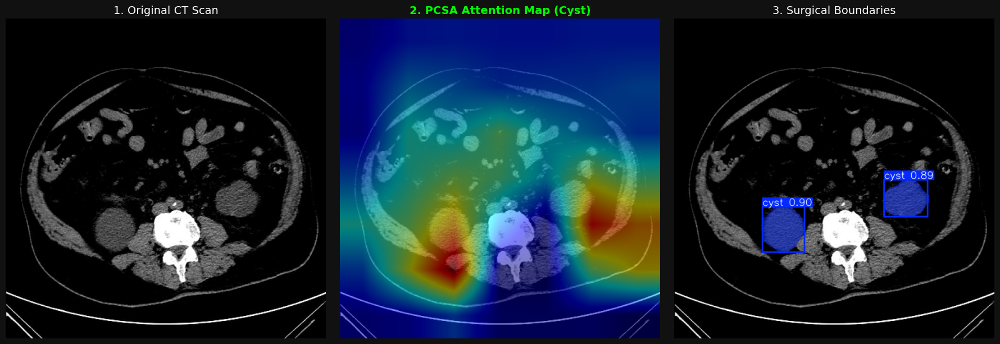


📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding...
✅ End-to-End Pipeline Complete! Hover your mouse over the floating pathology below:


In [ ]:
import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

# Grad-CAM Imports
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the Complete AI Hospital Mainframe...")

# ==========================================
# 1. LOAD NLP MEDICAL SCRIBE
# ==========================================
print("📚 Loading Medical NLP Engine...")
nlp_ner = pipeline(
    "ner",
    model="d4data/biomedical-ner-all",
    tokenizer="d4data/biomedical-ner-all",
    aggregation_strategy="simple"
)

patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""

extracted_entities = nlp_ner(patient_notes)

# Clean up the '##' subwords and format into a beautiful HTML string for the 3D Plot
entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "") # Remove subword artifacts
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words) # Clean joining
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"


# ==========================================
# 2. LOAD VISION & EXPLAINABILITY MODELS
# ==========================================
print("👁️ Loading Vision Models...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval() # Assumes PCSA is loaded

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")


# ==========================================
# 3. EXECUTE THE MASTER PIPELINE
# ==========================================
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    # --- STAGE 1: DIAGNOSIS & HEATMAP ---
    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # --- STAGE 2: SEGMENTATION ---
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # Print 1x3 Dashboard
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img)
    axes[0].set_title("1. Original CT Scan", color='white', fontsize=14)
    axes[0].axis('off')

    axes[1].imshow(cam_image)
    axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold')
    axes[1].axis('off')

    axes[2].imshow(annotated_img)
    axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14)
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    # --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
    if yolo_results is not None and yolo_results[0].masks is not None:
        print("\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding...")
        fig_3d = go.Figure()

        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names

        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            x_coords, y_coords = mask[:, 0], mask[:, 1]

            if name in ['tumor', 'cyst']:
                z_coords = np.ones_like(x_coords) * z_offset
                fig_3d.add_trace(go.Scatter3d(
                    x=x_coords, y=y_coords, z=z_coords,
                    mode='lines+markers',
                    marker=dict(size=3, color=plot_color),
                    line=dict(color=plot_color, width=5),
                    name=f"Extracted {name.capitalize()}",
                    text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                    hoverinfo='text'
                ))
            else:
                z_coords = np.zeros_like(x_coords)
                fig_3d.add_trace(go.Scatter3d(
                    x=x_coords, y=y_coords, z=z_coords,
                    mode='lines+markers',
                    marker=dict(size=3, color='#00ccff'),
                    line=dict(color='#00ccff', width=5),
                    name="Healthy Kidney"
                ))

        fig_3d.update_layout(
            title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
            scene=dict(
                xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
                xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
            ),
            paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
        )
        print("✅ End-to-End Pipeline Complete! Hover your mouse over the floating pathology below:")
        fig_3d.show()

🏥 Initializing the Complete AI Hospital Mainframe...
📚 Loading Medical NLP Engine...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

👁️ Loading Vision Models...

🔬 Analyzing Scan: Cyst-2091-_jpg.rf.a70cd81b8b8086b15407f981cd2b2d05.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 100.00%)


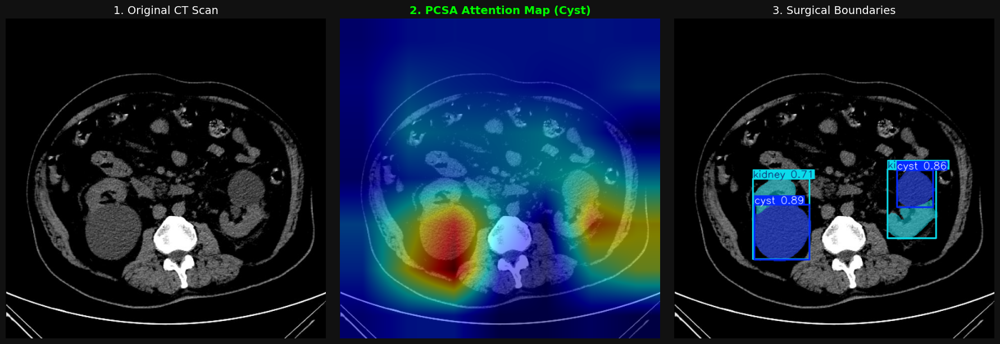


📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding...
✅ End-to-End Pipeline Complete! Hover your mouse over the floating pathology below:


In [ ]:
import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio                   # <--- NEW: Import Plotly IO
pio.renderers.default = 'colab'           # <--- NEW: Force Colab Renderer
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

# Grad-CAM Imports
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the Complete AI Hospital Mainframe...")

# ==========================================
# 1. LOAD NLP MEDICAL SCRIBE
# ==========================================
print("📚 Loading Medical NLP Engine...")
nlp_ner = pipeline(
    "ner",
    model="d4data/biomedical-ner-all",
    tokenizer="d4data/biomedical-ner-all",
    aggregation_strategy="simple"
)

patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""

extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

# ==========================================
# 2. LOAD VISION & EXPLAINABILITY MODELS
# ==========================================
print("👁️ Loading Vision Models...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# ==========================================
# 3. EXECUTE THE MASTER PIPELINE
# ==========================================
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    # --- STAGE 1: DIAGNOSIS & HEATMAP ---
    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]

    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # --- STAGE 2: SEGMENTATION ---
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = yolo_results[0].plot()
        annotated_img = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # Print 1x3 Dashboard
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img)
    axes[0].set_title("1. Original CT Scan", color='white', fontsize=14)
    axes[0].axis('off')

    axes[1].imshow(cam_image)
    axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold')
    axes[1].axis('off')

    axes[2].imshow(annotated_img)
    axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14)
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    # --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
    if yolo_results is not None and yolo_results[0].masks is not None:
        print("\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding...")
        fig_3d = go.Figure()

        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names

        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            x_coords, y_coords = mask[:, 0], mask[:, 1]

            if name in ['tumor', 'cyst']:
                z_coords = np.ones_like(x_coords) * z_offset
                fig_3d.add_trace(go.Scatter3d(
                    x=x_coords, y=y_coords, z=z_coords,
                    mode='lines+markers',
                    marker=dict(size=3, color=plot_color),
                    line=dict(color=plot_color, width=5),
                    name=f"Extracted {name.capitalize()}",
                    text=[hover_html] * len(x_coords),
                    hoverinfo='text'
                ))
            else:
                z_coords = np.zeros_like(x_coords)
                fig_3d.add_trace(go.Scatter3d(
                    x=x_coords, y=y_coords, z=z_coords,
                    mode='lines+markers',
                    marker=dict(size=3, color='#00ccff'),
                    line=dict(color='#00ccff', width=5),
                    name="Healthy Kidney"
                ))

        fig_3d.update_layout(
            title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
            scene=dict(
                xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
                xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
                zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
            ),
            paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
        )
        print("✅ End-to-End Pipeline Complete! Hover your mouse over the floating pathology below:")

        # <--- NEW: Enforce the Colab renderer on the final output
        fig_3d.show(renderer="colab")

🏥 Initializing the AI Hospital Mainframe (Stage 1 & 2)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


🔬 Analyzing Scan: Cyst-2084-_jpg.rf.7e46c5f24b9b326b6fc2c6ea0d65076a.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 100.00%)


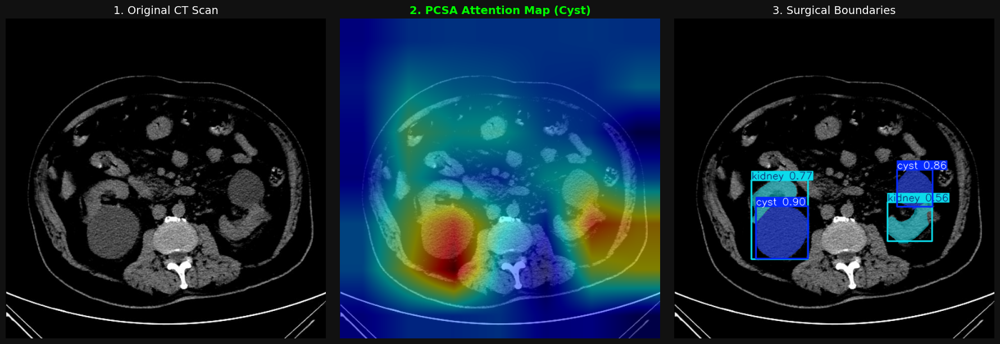

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1 & 2)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # 1x3 Dashboard
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#111111')
    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color=plot_color),
                line=dict(color=plot_color, width=5),
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color='#00ccff'),
                line=dict(color='#00ccff', width=5),
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    fig_3d.update_layout(
        title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for Cyst...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1 & 2)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 45 - Year - Old
   [SEX] -> Male
   [SEVERITY] -> Severe
   [BIOLOGICAL_STRUCTURE] -> Flankabdomenbosniarenal
   [SIGN_SYMPTOM] -> Painhematurialesioncyst
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 4Cm
   [PERSONAL_BACKGROUND] -> K
   [DETAILED_DESCRIPTION] -> Category Iii Cy Stic Partial
   [HISTORY] -> Hypertension
   [MEDICATION] -> Lisinop
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🔬 Analyzing Scan: Cyst-768-_jpg.rf.a75a6a126396562e9481f66d6b065a81.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 99.15%)


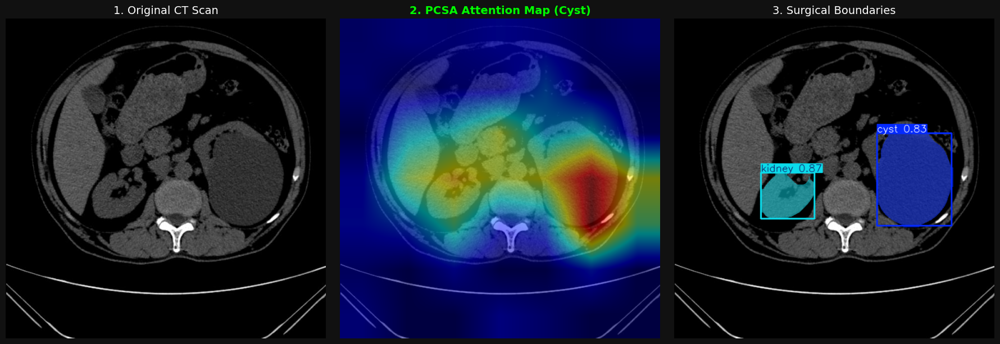

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1 & 2)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

# ---> NEW: Print the NLP extraction to the console <---
print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    print(f"   [{grp}] -> {combined_words.title()}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # 1x3 Dashboard
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#111111')
    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color=plot_color),
                line=dict(color=plot_color, width=5),
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color='#00ccff'),
                line=dict(color='#00ccff', width=5),
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    fig_3d.update_layout(
        title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for Cyst...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1 & 2)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 45 - Year - Old
   [SEX] -> Male
   [SEVERITY] -> Severe
   [BIOLOGICAL_STRUCTURE] -> Flankabdomenbosniarenal
   [SIGN_SYMPTOM] -> Painhematurialesioncyst
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 4Cm
   [PERSONAL_BACKGROUND] -> K
   [DETAILED_DESCRIPTION] -> Category Iii Cy Stic Partial
   [HISTORY] -> Hypertension
   [MEDICATION] -> Lisinop
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🔬 Analyzing Scan: Cyst-761-_jpg.rf.d0342c3d3a4d8e0e0a766c85dc401437.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 100.00%)


adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)


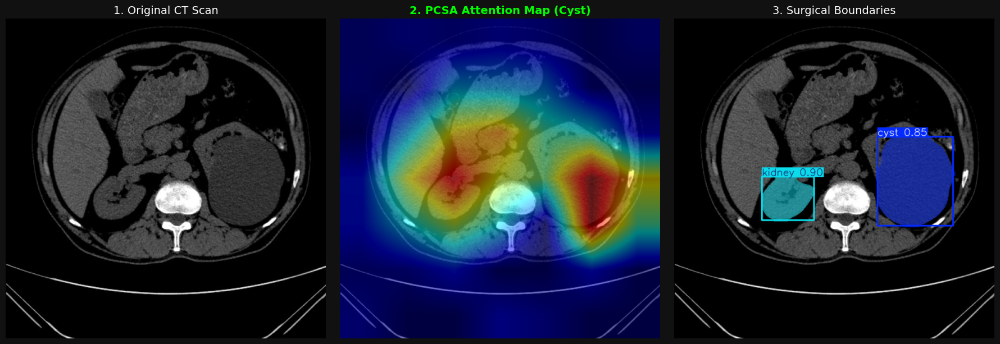

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1 & 2)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

patient_notes = """
Patient is a 45-year-old male presenting with severe flank pain and hematuria.
A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
Patient has a history of hypertension managed with Lisinopril.
Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

# ---> NEW: Print the NLP extraction to the console <---
print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    print(f"   [{grp}] -> {combined_words.title()}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # 1x3 Dashboard
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('#111111')
    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color=plot_color),
                line=dict(color=plot_color, width=5),
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color='#00ccff'),
                line=dict(color='#00ccff', width=5),
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    fig_3d.update_layout(
        title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for Cyst...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 45 - Year - Old
   [SEX] -> Male
   [SEVERITY] -> Severe
   [BIOLOGICAL_STRUCTURE] -> Flankabdomenbosniarenal
   [SIGN_SYMPTOM] -> Painhematurialesioncyst
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 4Cm
   [PERSONAL_BACKGROUND] -> K
   [DETAILED_DESCRIPTION] -> Category Iii Cy Stic Partial
   [HISTORY] -> Hypertension
   [MEDICATION] -> Lisinop
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🔬 Analyzing Scan: Cyst-824-_jpg.rf.ca34af9f9d498e893e477df22ad0d96f.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 99.99%)


/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:865: UserWarning:

adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)



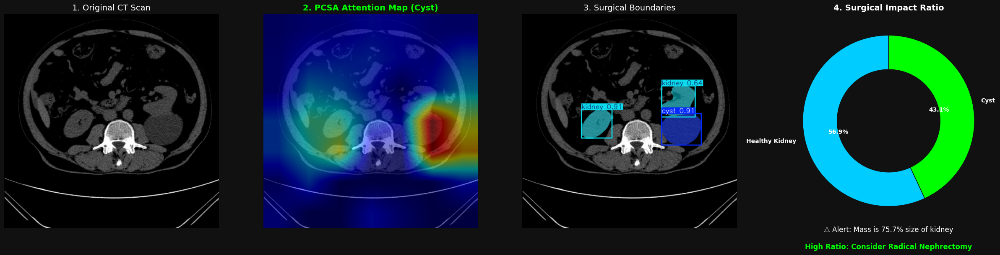

In [ ]:
  # --- INSTALL DEPENDENCIES FIRST ---
  !pip install -q grad-cam transformers

  import torch
  import cv2
  from PIL import Image
  from torchvision import transforms
  import matplotlib.pyplot as plt
  from ultralytics import YOLO
  from transformers import pipeline
  import glob
  import random
  import numpy as np

  from pytorch_grad_cam import GradCAM
  from pytorch_grad_cam.utils.image import show_cam_on_image
  from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

  print("🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...")

  # --- 1. LOAD NLP MEDICAL SCRIBE ---
  nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

  patient_notes = """
  Patient is a 45-year-old male presenting with severe flank pain and hematuria.
  A CT scan of the abdomen revealed a 4cm Bosniak Category III cystic lesion on the left kidney.
  Patient has a history of hypertension managed with Lisinopril.
  Recommended partial nephrectomy to remove the cyst and preserve healthy renal tissue.
  """
  extracted_entities = nlp_ner(patient_notes)

  entity_dict = {}
  for entity in extracted_entities:
      grp = entity['entity_group'].upper()
      word = entity['word'].replace("##", "")
      if grp not in entity_dict:
          entity_dict[grp] = []
      entity_dict[grp].append(word)

  print("\n📋 PubMedBERT Extracted Clinical Context:")
  for grp, words in entity_dict.items():
      combined_words = "".join(words) if " " not in words[0] else " ".join(words)
      print(f"   [{grp}] -> {combined_words.title()}")
  print("-" * 60)

  hover_html = "<b>Patient Clinical Context:</b><br>"
  for grp, words in entity_dict.items():
      combined_words = "".join(words) if " " not in words[0] else " ".join(words)
      hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

  # --- 2. LOAD VISION MODELS ---
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
  pcsa_classifier.eval()

  transform = transforms.Compose([
      transforms.Resize((224, 224)),
      transforms.ToTensor(),
      transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
  ])
  class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

  tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
  cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

  # --- 3. EXECUTE INFERENCE ---
  available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
  if len(available_images) == 0:
      print("❌ Error: Colab's temporary storage is empty.")
  else:
      sample_scan = random.choice(available_images)
      print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
      print("-" * 60)

      img = Image.open(sample_scan).convert('RGB')
      input_tensor = transform(img).unsqueeze(0).to(device)

      with torch.no_grad():
          outputs = pcsa_classifier(input_tensor)
          probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
          confidence, predicted_idx = torch.max(probabilities, 0)
          diagnosis = class_names[predicted_idx.item()]

      print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

      # Grad-CAM
      target_layers = [pcsa_classifier.stage4]
      cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
      targets = [ClassifierOutputTarget(predicted_idx.item())]
      grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
      grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
      img_float = np.float32(img) / 255.0
      cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

      # YOLO Routing
      yolo_results = None
      z_offset = 0
      title_color = '#00ccff'
      plot_color = '#00ccff'

      if diagnosis == "Tumor":
          yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
          annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
          title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
      elif diagnosis == "Cyst":
          yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
          annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
          title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
      else:
          annotated_img = np.array(img)

      # --- 4. CLINICAL SIZING MODULE ---
      kidney_total_area = 0.0
      pathology_total_area = 0.0
      pathology_name = diagnosis

      if yolo_results is not None and yolo_results[0].masks is not None:
          masks = yolo_results[0].masks.xy
          classes = yolo_results[0].boxes.cls
          names = yolo_results[0].names
          for i, mask in enumerate(masks):
              cls_id = int(classes[i].item())
              name = names[cls_id]
              area = cv2.contourArea(mask.astype(np.float32))
              if name == 'kidney':
                  kidney_total_area += area
              elif name in ['tumor', 'cyst']:
                  pathology_total_area += area

      consumption_ratio = 0
      recommendation = "No significant mass detected."
      if kidney_total_area > 0 and pathology_total_area > 0:
          consumption_ratio = (pathology_total_area / kidney_total_area) * 100
          if consumption_ratio > 30.0:
              recommendation = "High Ratio: Consider Radical Nephrectomy"
          else:
              recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

      # Inject the sizing data straight into the 3D NLP Hover Text
      hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
      if pathology_total_area > 0:
          hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
          hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
          hover_html += f"• Protocol: {recommendation}<br>"

      # --- 5. 1x4 DASHBOARD PLOTTING ---
      fig, axes = plt.subplots(1, 4, figsize=(24, 6)) # We extended this to 1x4!
      fig.patch.set_facecolor('#111111')

      axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
      axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
      axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

      # The New Donut Chart Visualization
      axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
      if pathology_total_area > 0:
          sizes = [kidney_total_area, pathology_total_area]
          labels = ['Healthy Kidney', pathology_name]
          colors = ['#00ccff', plot_color]

          # Draw Donut
          wedges, texts, autotexts = axes[3].pie(
              sizes, labels=labels, colors=colors, autopct='%1.1f%%',
              startangle=90, textprops=dict(color="w", weight="bold"),
              wedgeprops=dict(width=0.4, edgecolor='#111111')
          )

          # Add the Clinical Alert Text
          axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
          axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
      else:
          axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
          axes[3].axis('off')

      plt.tight_layout()
      plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color=plot_color),
                line=dict(color=plot_color, width=5),
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color='#00ccff'),
                line=dict(color='#00ccff', width=5),
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    fig_3d.update_layout(
        title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for Cyst...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 55 - Year - Old
   [SEX] -> Female
   [SIGN_SYMPTOM] -> Hematuriamassmeta
   [DETAILED_DESCRIPTION] -> Rightsolidhypervas
   [BIOLOGICAL_STRUCTURE] -> Sidedflankabdomen
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 5Cm
   [DISEASE_DISORDER] -> Renal Cell Carcinoma Rc 2 Diabetes
   [HISTORY] -> Type
   [MEDICATION] -> Met
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🔬 Analyzing Scan: Cyst-49-_jpg.rf.3e2e503f7bc8aeca4c29c571ae23dbe8.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Cyst (Confidence: 99.16%)


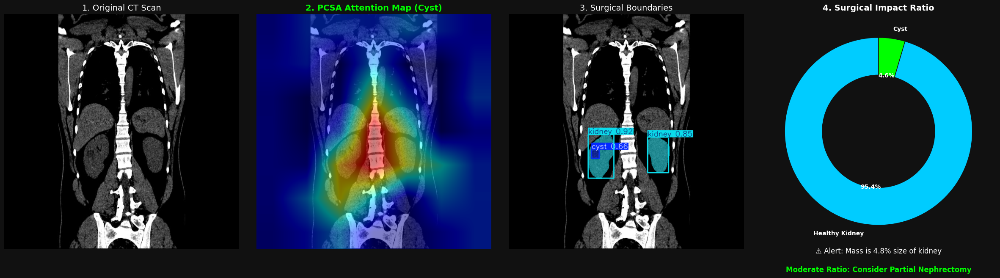

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

# UPDATED: We swapped the notes to a severe Renal Cell Carcinoma (Tumor) case!
patient_notes = """
Patient is a 55-year-old female presenting with hematuria and right-sided flank pain.
A CT scan of the abdomen revealed a 5cm solid, hypervascular mass on the right kidney, highly suspicious for Renal Cell Carcinoma (RCC).
Patient has a history of type 2 diabetes managed with Metformin.
Recommended radical nephrectomy due to the mass-to-kidney size ratio and risk of metastasis.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    print(f"   [{grp}] -> {combined_words.title()}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # --- 4. CLINICAL SIZING MODULE ---
    kidney_total_area = 0.0
    pathology_total_area = 0.0
    pathology_name = diagnosis

    if yolo_results is not None and yolo_results[0].masks is not None:
        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names
        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            area = cv2.contourArea(mask.astype(np.float32))
            if name == 'kidney':
                kidney_total_area += area
            elif name in ['tumor', 'cyst']:
                pathology_total_area += area

    consumption_ratio = 0
    recommendation = "No significant mass detected."
    if kidney_total_area > 0 and pathology_total_area > 0:
        consumption_ratio = (pathology_total_area / kidney_total_area) * 100
        if consumption_ratio > 30.0:
            recommendation = "High Ratio: Consider Radical Nephrectomy"
        else:
            recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

    # Inject the sizing data straight into the 3D NLP Hover Text
    hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
    if pathology_total_area > 0:
        hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
        hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
        hover_html += f"• Protocol: {recommendation}<br>"

    # --- 5. 1x4 DASHBOARD PLOTTING ---
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

    # The New Donut Chart Visualization
    axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
    if pathology_total_area > 0:
        sizes = [kidney_total_area, pathology_total_area]
        labels = ['Healthy Kidney', pathology_name]
        colors = ['#00ccff', plot_color]

        wedges, texts, autotexts = axes[3].pie(
            sizes, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops=dict(color="w", weight="bold"),
            wedgeprops=dict(width=0.4, edgecolor='#111111')
        )

        axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
        axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
    else:
        axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
        axes[3].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import os

print("🧱 Initializing 3D Mesh Exporter...")

# The name of the file we are creating
obj_filename = "/content/Patient_Surgical_Mesh.obj"

if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    vertex_offset = 1 # OBJ files start counting at 1, not 0

    with open(obj_filename, "w") as f:
        f.write("# Auto-generated Medical 3D Mesh by PCSA-KidneyNeXt Pipeline\n")
        f.write("o Surgical_Environment\n\n")

        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]

            print(f"📐 Extruding 3D geometry for: {name.capitalize()}")
            f.write(f"g {name}_{i}\n") # Create a group for each organ/mass

            # 1. Downscale the pixels so the mesh isn't 600 meters wide in Blender!
            scale = 0.02
            x_coords = mask[:, 0] * scale
            y_coords = mask[:, 1] * scale

            # 2. Determine 3D thickness (Elevate the pathology so it pops out)
            z_bottom = 0.0
            z_top = 1.5 if name in ['tumor', 'cyst'] else 0.5

            num_points = len(x_coords)

            # 3. Write the Bottom Vertices (v)
            for x, y in zip(x_coords, y_coords):
                f.write(f"v {x:.4f} {y:.4f} {z_bottom:.4f}\n")

            # 4. Write the Top Vertices (v)
            for x, y in zip(x_coords, y_coords):
                f.write(f"v {x:.4f} {y:.4f} {z_top:.4f}\n")

            # 5. Write the Faces (f) to build the walls of the mesh
            for j in range(num_points):
                next_j = (j + 1) % num_points
                # Connect bottom-left, bottom-right, top-right, top-left
                v1 = vertex_offset + j
                v2 = vertex_offset + next_j
                v3 = vertex_offset + num_points + next_j
                v4 = vertex_offset + num_points + j
                f.write(f"f {v1} {v2} {v3} {v4}\n")

            # 6. Write the Top and Bottom "Cap" Faces
            bottom_face = " ".join([str(vertex_offset + j) for j in reversed(range(num_points))])
            top_face = " ".join([str(vertex_offset + num_points + j) for j in range(num_points)])

            f.write(f"f {bottom_face}\n")
            f.write(f"f {top_face}\n\n")

            # Update the global vertex count for the next organ
            vertex_offset += 2 * num_points

    print("-" * 50)
    print(f"✅ SUCCESS! 3D Mesh exported to: {obj_filename}")
    print("📥 You can now download it from the folder icon on the left side of Colab!")

else:
    print("⚠️ No YOLO Sizing Data found. Please run the Master Pipeline cell first.")

🧱 Initializing 3D Mesh Exporter...
📐 Extruding 3D geometry for: Kidney
📐 Extruding 3D geometry for: Kidney
📐 Extruding 3D geometry for: Cyst
--------------------------------------------------
✅ SUCCESS! 3D Mesh exported to: /content/Patient_Surgical_Mesh.obj
📥 You can now download it from the folder icon on the left side of Colab!


In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color=plot_color),
                line=dict(color=plot_color, width=5),
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=3, color='#00ccff'),
                line=dict(color='#00ccff', width=5),
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    fig_3d.update_layout(
        title=f"Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})",
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=50)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting 3D Spatial Geometry with NLP Embedding for Cyst...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 55 - Year - Old
   [SEX] -> Female
   [SIGN_SYMPTOM] -> Hematuriamassmeta
   [DETAILED_DESCRIPTION] -> Rightsolidhypervas
   [BIOLOGICAL_STRUCTURE] -> Sidedflankabdomen
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 5Cm
   [DISEASE_DISORDER] -> Renal Cell Carcinoma Rc 2 Diabetes
   [HISTORY] -> Type
   [MEDICATION] -> Met
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🔬 Analyzing Scan: Tumor-832-_jpg.rf.a8206115c23a528ccf6537d90ceccc8f.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Tumor (Confidence: 100.00%)


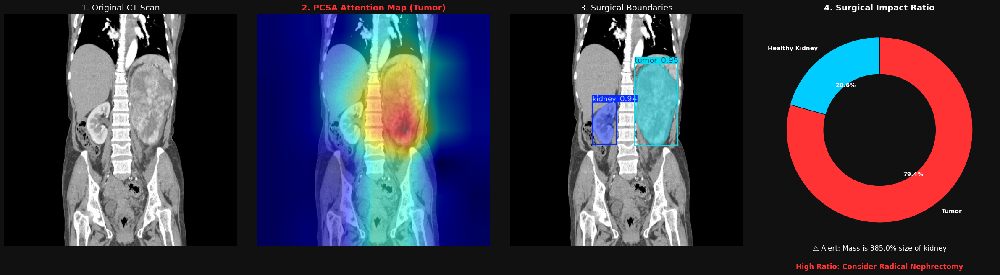

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

# UPDATED: We swapped the notes to a severe Renal Cell Carcinoma (Tumor) case!
patient_notes = """
Patient is a 55-year-old female presenting with hematuria and right-sided flank pain.
A CT scan of the abdomen revealed a 5cm solid, hypervascular mass on the right kidney, highly suspicious for Renal Cell Carcinoma (RCC).
Patient has a history of type 2 diabetes managed with Metformin.
Recommended radical nephrectomy due to the mass-to-kidney size ratio and risk of metastasis.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    print(f"   [{grp}] -> {combined_words.title()}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*[Tt]umor*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # --- 4. CLINICAL SIZING MODULE ---
    kidney_total_area = 0.0
    pathology_total_area = 0.0
    pathology_name = diagnosis

    if yolo_results is not None and yolo_results[0].masks is not None:
        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names
        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            area = cv2.contourArea(mask.astype(np.float32))
            if name == 'kidney':
                kidney_total_area += area
            elif name in ['tumor', 'cyst']:
                pathology_total_area += area

    consumption_ratio = 0
    recommendation = "No significant mass detected."
    if kidney_total_area > 0 and pathology_total_area > 0:
        consumption_ratio = (pathology_total_area / kidney_total_area) * 100
        if consumption_ratio > 30.0:
            recommendation = "High Ratio: Consider Radical Nephrectomy"
        else:
            recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

    # Inject the sizing data straight into the 3D NLP Hover Text
    hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
    if pathology_total_area > 0:
        hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
        hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
        hover_html += f"• Protocol: {recommendation}<br>"

    # --- 5. 1x4 DASHBOARD PLOTTING ---
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

    # The New Donut Chart Visualization
    axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
    if pathology_total_area > 0:
        sizes = [kidney_total_area, pathology_total_area]
        labels = ['Healthy Kidney', pathology_name]
        colors = ['#00ccff', plot_color]

        wedges, texts, autotexts = axes[3].pie(
            sizes, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops=dict(color="w", weight="bold"),
            wedgeprops=dict(width=0.4, edgecolor='#111111')
        )

        axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
        axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
    else:
        axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
        axes[3].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color=plot_color),
                line=dict(color=plot_color, width=4),
                surfaceaxis=2, # <--- NEW: Fills the polygon to make it a solid object!
                surfacecolor=plot_color,
                opacity=0.85,  # Solid, highly visible pathology
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color='#00ccff'),
                line=dict(color='#00ccff', width=4),
                surfaceaxis=2, # <--- NEW: Fills the healthy kidney!
                surfacecolor='#00ccff',
                opacity=0.3,   # <--- NEW: Makes the healthy tissue look like transparent glass
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    # Dynamically inject the Surgical Sizing Recommendation into the 3D Title
    plot_title = f"<b>Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})</b>"
    if 'recommendation' in locals():
        plot_title += f"<br><sup><i>Protocol: {recommendation}</i></sup>"

    fig_3d.update_layout(
        title=plot_title,
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=70)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for Tumor...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 55 - Year - Old
   [SEX] -> Female
   [SIGN_SYMPTOM] -> Hematuriamassmeta
   [DETAILED_DESCRIPTION] -> Rightsolidhypervas
   [BIOLOGICAL_STRUCTURE] -> Sidedflankabdomen
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 5Cm
   [DISEASE_DISORDER] -> Renal Cell Carcinoma Rc 2 Diabetes
   [HISTORY] -> Type
   [MEDICATION] -> Met
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🔬 Analyzing Scan: Tumor-1400-_jpg.rf.b7b630c02eab16995b2dc0e47d508adb.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Tumor (Confidence: 100.00%)


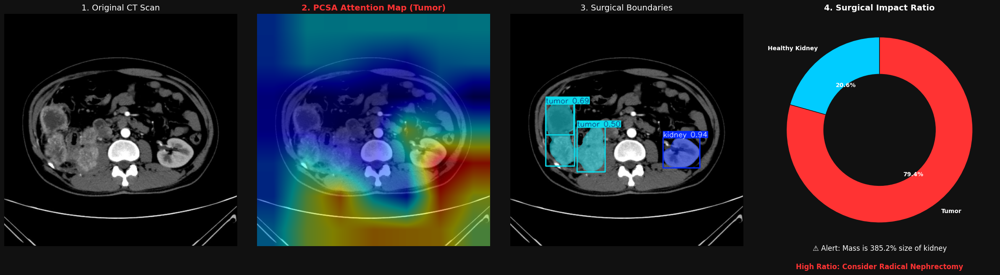

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

# UPDATED: We swapped the notes to a severe Renal Cell Carcinoma (Tumor) case!
patient_notes = """
Patient is a 55-year-old female presenting with hematuria and right-sided flank pain.
A CT scan of the abdomen revealed a 5cm solid, hypervascular mass on the right kidney, highly suspicious for Renal Cell Carcinoma (RCC).
Patient has a history of type 2 diabetes managed with Metformin.
Recommended radical nephrectomy due to the mass-to-kidney size ratio and risk of metastasis.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    print(f"   [{grp}] -> {combined_words.title()}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = "".join(words) if " " not in words[0] else " ".join(words)
    hover_html += f"• <b>{grp}:</b> {combined_words.title()}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*[Tt]umor*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # --- 4. CLINICAL SIZING MODULE ---
    kidney_total_area = 0.0
    pathology_total_area = 0.0
    pathology_name = diagnosis

    if yolo_results is not None and yolo_results[0].masks is not None:
        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names
        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            area = cv2.contourArea(mask.astype(np.float32))
            if name == 'kidney':
                kidney_total_area += area
            elif name in ['tumor', 'cyst']:
                pathology_total_area += area

    consumption_ratio = 0
    recommendation = "No significant mass detected."
    if kidney_total_area > 0 and pathology_total_area > 0:
        consumption_ratio = (pathology_total_area / kidney_total_area) * 100
        if consumption_ratio > 30.0:
            recommendation = "High Ratio: Consider Radical Nephrectomy"
        else:
            recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

    # Inject the sizing data straight into the 3D NLP Hover Text
    hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
    if pathology_total_area > 0:
        hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
        hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
        hover_html += f"• Protocol: {recommendation}<br>"

    # --- 5. 1x4 DASHBOARD PLOTTING ---
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

    # The New Donut Chart Visualization
    axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
    if pathology_total_area > 0:
        sizes = [kidney_total_area, pathology_total_area]
        labels = ['Healthy Kidney', pathology_name]
        colors = ['#00ccff', plot_color]

        wedges, texts, autotexts = axes[3].pie(
            sizes, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops=dict(color="w", weight="bold"),
            wedgeprops=dict(width=0.4, edgecolor='#111111')
        )

        axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
        axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
    else:
        axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
        axes[3].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color=plot_color),
                line=dict(color=plot_color, width=4),
                surfaceaxis=2, # <--- NEW: Fills the polygon to make it a solid object!
                surfacecolor=plot_color,
                opacity=0.85,  # Solid, highly visible pathology
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color='#00ccff'),
                line=dict(color='#00ccff', width=4),
                surfaceaxis=2, # <--- NEW: Fills the healthy kidney!
                surfacecolor='#00ccff',
                opacity=0.3,   # <--- NEW: Makes the healthy tissue look like transparent glass
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    # Dynamically inject the Surgical Sizing Recommendation into the 3D Title
    plot_title = f"<b>Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})</b>"
    if 'recommendation' in locals():
        plot_title += f"<br><sup><i>Protocol: {recommendation}</i></sup>"

    fig_3d.update_layout(
        title=plot_title,
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=70)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for Tumor...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 55 - Year - Old
   [SEX] -> Female
   [SIGN_SYMPTOM] -> Hem, Aturia, Mass, Meta
   [DETAILED_DESCRIPTION] -> Right, Solid, Hyper, Vas
   [BIOLOGICAL_STRUCTURE] -> Sided, Flank, Abdomen
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 5Cm
   [DISEASE_DISORDER] -> Renal Cell Carcinoma, Rc, 2 Diabetes
   [HISTORY] -> Type
   [MEDICATION] -> Met
   [THERAPEUTIC_PROCEDURE] -> Ne, Ph, Re, Ctomy
------------------------------------------------------------

🔬 Analyzing Scan: Tumor-61-_jpg.rf.479ea8caf3d589ecf363c31580b8c6fa.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Tumor (Confidence: 100.00%)


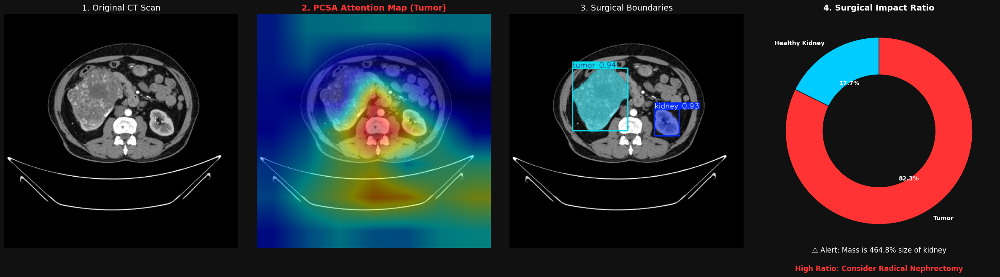

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformersrobo

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

# UPDATED: We swapped the notes to a severe Renal Cell Carcinoma (Tumor) case!
patient_notes = """
Patient is a 55-year-old female presenting with hematuria and right-sided flank pain.
A CT scan of the abdomen revealed a 5cm solid, hypervascular mass on the right kidney, highly suspicious for Renal Cell Carcinoma (RCC).
Patient has a history of type 2 diabetes managed with Metformin.
Recommended radical nephrectomy due to the mass-to-kidney size ratio and risk of metastasis.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    word = entity['word'].replace("##", "")
    if grp not in entity_dict:
        entity_dict[grp] = []
    entity_dict[grp].append(word)

# --- REPLACED PRINTING LOGIC ---
print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    # Use a comma and space to separate multiple medical terms cleanly
    combined_words = ", ".join([w.strip().title() for w in words])
    print(f"   [{grp}] -> {combined_words}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    combined_words = ", ".join([w.strip().title() for w in words])
    hover_html += f"• <b>{grp}:</b> {combined_words}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*[Tt]umor*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # --- 4. CLINICAL SIZING MODULE ---
    kidney_total_area = 0.0
    pathology_total_area = 0.0
    pathology_name = diagnosis

    if yolo_results is not None and yolo_results[0].masks is not None:
        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names
        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            area = cv2.contourArea(mask.astype(np.float32))
            if name == 'kidney':
                kidney_total_area += area
            elif name in ['tumor', 'cyst']:
                pathology_total_area += area

    consumption_ratio = 0
    recommendation = "No significant mass detected."
    if kidney_total_area > 0 and pathology_total_area > 0:
        consumption_ratio = (pathology_total_area / kidney_total_area) * 100
        if consumption_ratio > 30.0:
            recommendation = "High Ratio: Consider Radical Nephrectomy"
        else:
            recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

    # Inject the sizing data straight into the 3D NLP Hover Text
    hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
    if pathology_total_area > 0:
        hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
        hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
        hover_html += f"• Protocol: {recommendation}<br>"

    # --- 5. 1x4 DASHBOARD PLOTTING ---
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

    # The New Donut Chart Visualization
    axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
    if pathology_total_area > 0:
        sizes = [kidney_total_area, pathology_total_area]
        labels = ['Healthy Kidney', pathology_name]
        colors = ['#00ccff', plot_color]

        wedges, texts, autotexts = axes[3].pie(
            sizes, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops=dict(color="w", weight="bold"),
            wedgeprops=dict(width=0.4, edgecolor='#111111')
        )

        axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
        axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
    else:
        axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
        axes[3].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color=plot_color),
                line=dict(color=plot_color, width=4),
                surfaceaxis=2, # <--- NEW: Fills the polygon to make it a solid object!
                surfacecolor=plot_color,
                opacity=0.85,  # Solid, highly visible pathology
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color='#00ccff'),
                line=dict(color='#00ccff', width=4),
                surfaceaxis=2, # <--- NEW: Fills the healthy kidney!
                surfacecolor='#00ccff',
                opacity=0.3,   # <--- NEW: Makes the healthy tissue look like transparent glass
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    # Dynamically inject the Surgical Sizing Recommendation into the 3D Title
    plot_title = f"<b>Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})</b>"
    if 'recommendation' in locals():
        plot_title += f"<br><sup><i>Protocol: {recommendation}</i></sup>"

    fig_3d.update_layout(
        title=plot_title,
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=70)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for Tumor...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 55 - Year - Old
   [SEX] -> Female
   [SIGN_SYMPTOM] -> Hematuria, Mass, Meta
   [DETAILED_DESCRIPTION] -> Right, Solid, Hypervas
   [BIOLOGICAL_STRUCTURE] -> Sided, Flank, Abdomen
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 5Cm
   [DISEASE_DISORDER] -> Renal Cell Carcinoma, Rc, 2 Diabetes
   [HISTORY] -> Type
   [MEDICATION] -> Met
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🔬 Analyzing Scan: Tumor-656-_jpg.rf.24711d1ecd10232c39b001becef31365.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Tumor (Confidence: 100.00%)


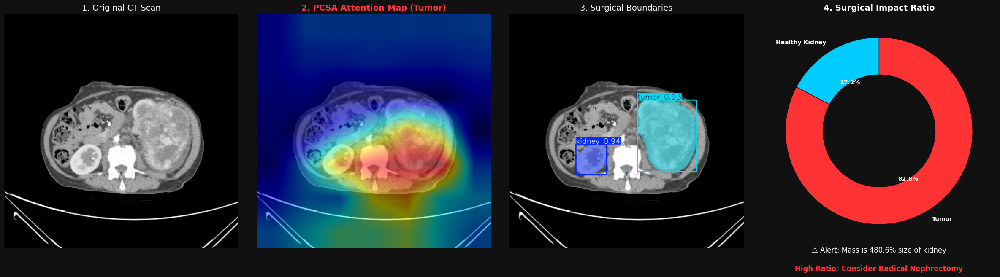

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Stage 1, 2 & Sizing)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

# Patient notes for a severe Renal Cell Carcinoma (Tumor) case
patient_notes = """
Patient is a 55-year-old female presenting with hematuria and right-sided flank pain.
A CT scan of the abdomen revealed a 5cm solid, hypervascular mass on the right kidney, highly suspicious for Renal Cell Carcinoma (RCC).
Patient has a history of type 2 diabetes managed with Metformin.
Recommended radical nephrectomy due to the mass-to-kidney size ratio and risk of metastasis.
"""
extracted_entities = nlp_ner(patient_notes)

# --- CORRECTED NLP WORD-STITCHING LOGIC ---
entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    raw_word = entity['word']
    clean_word = raw_word.replace("##", "").strip()

    if grp not in entity_dict:
        entity_dict[grp] = []

    # WordPiece Subword Logic: Glue sub-words together, separate distinct words
    if raw_word.startswith("##") and len(entity_dict[grp]) > 0:
        entity_dict[grp][-1] += clean_word # Glue to previous word
    else:
        entity_dict[grp].append(clean_word) # Add as new separate word

print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    # Remove duplicates, capitalize, and join with a clean comma
    unique_words = list(dict.fromkeys([w.title() for w in words]))
    combined_words = ", ".join(unique_words)
    print(f"   [{grp}] -> {combined_words}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    unique_words = list(dict.fromkeys([w.title() for w in words]))
    combined_words = ", ".join(unique_words)
    hover_html += f"• <b>{grp}:</b> {combined_words}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
# Looking specifically for Tumor images
available_images = glob.glob('/content/datasets/*[Tt]umor*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # --- 4. CLINICAL SIZING MODULE ---
    kidney_total_area = 0.0
    pathology_total_area = 0.0
    pathology_name = diagnosis

    if yolo_results is not None and yolo_results[0].masks is not None:
        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names
        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            area = cv2.contourArea(mask.astype(np.float32))
            if name == 'kidney':
                kidney_total_area += area
            elif name in ['tumor', 'cyst']:
                pathology_total_area += area

    consumption_ratio = 0
    recommendation = "No significant mass detected."
    if kidney_total_area > 0 and pathology_total_area > 0:
        consumption_ratio = (pathology_total_area / kidney_total_area) * 100
        if consumption_ratio > 30.0:
            recommendation = "High Ratio: Consider Radical Nephrectomy"
        else:
            recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

    # Inject the sizing data straight into the 3D NLP Hover Text
    hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
    if pathology_total_area > 0:
        hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
        hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
        hover_html += f"• Protocol: {recommendation}<br>"

    # --- 5. 1x4 DASHBOARD PLOTTING ---
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

    # The New Donut Chart Visualization
    axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
    if pathology_total_area > 0:
        sizes = [kidney_total_area, pathology_total_area]
        labels = ['Healthy Kidney', pathology_name]
        colors = ['#00ccff', plot_color]

        wedges, texts, autotexts = axes[3].pie(
            sizes, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops=dict(color="w", weight="bold"),
            wedgeprops=dict(width=0.4, edgecolor='#111111')
        )

        axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
        axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
    else:
        axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
        axes[3].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color=plot_color),
                line=dict(color=plot_color, width=4),
                surfaceaxis=2, # <--- NEW: Fills the polygon to make it a solid object!
                surfacecolor=plot_color,
                opacity=0.85,  # Solid, highly visible pathology
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color='#00ccff'),
                line=dict(color='#00ccff', width=4),
                surfaceaxis=2, # <--- NEW: Fills the healthy kidney!
                surfacecolor='#00ccff',
                opacity=0.3,   # <--- NEW: Makes the healthy tissue look like transparent glass
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    # Dynamically inject the Surgical Sizing Recommendation into the 3D Title
    plot_title = f"<b>Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})</b>"
    if 'recommendation' in locals():
        plot_title += f"<br><sup><i>Protocol: {recommendation}</i></sup>"

    fig_3d.update_layout(
        title=plot_title,
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=70)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for Tumor...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


🏥 Initializing the AI Hospital Mainframe (Diagnostics & Dietitian)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 55 - Year - Old
   [SEX] -> Female
   [SIGN_SYMPTOM] -> Hematuria, Mass, Meta
   [DETAILED_DESCRIPTION] -> Right, Solid, Hypervas
   [BIOLOGICAL_STRUCTURE] -> Sided, Flank, Abdomen
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 5Cm
   [DISEASE_DISORDER] -> Renal Cell Carcinoma, Rc, 2 Diabetes
   [HISTORY] -> Type
   [MEDICATION] -> Met
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🥗 AI Dietitian & Lifestyle Recommendations:
   🩸 Diabetic-Renal Diet: Strict glycemic control. Prioritize complex carbs (low GI) to prevent kidney strain.
   🥩 Post-Nephrectomy Nutrition: High-quality, lean protein for tissue repair. Limit processed red meats.
------------------------------------------------------------

🔬 Analyzing Scan: Tumor-626-_jpg.rf.ca33d7135ff9bb2d4b4c6e95acbb70ec.jpg
------------------------------------------------------------
➡️ Stage 1 Diagnosis: Tumor (Confidence: 100.

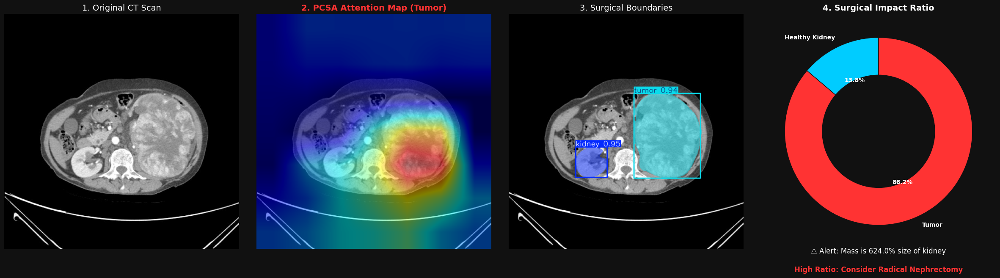

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print("🏥 Initializing the AI Hospital Mainframe (Diagnostics & Dietitian)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

patient_notes = """
Patient is a 55-year-old female presenting with hematuria and right-sided flank pain.
A CT scan of the abdomen revealed a 5cm solid, hypervascular mass on the right kidney, highly suspicious for Renal Cell Carcinoma (RCC).
Patient has a history of type 2 diabetes managed with Metformin.
Recommended radical nephrectomy due to the mass-to-kidney size ratio and risk of metastasis.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    raw_word = entity['word']
    clean_word = raw_word.replace("##", "").strip()

    if grp not in entity_dict:
        entity_dict[grp] = []

    if raw_word.startswith("##") and len(entity_dict[grp]) > 0:
        entity_dict[grp][-1] += clean_word
    else:
        entity_dict[grp].append(clean_word)

print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    unique_words = list(dict.fromkeys([w.title() for w in words]))
    combined_words = ", ".join(unique_words)
    print(f"   [{grp}] -> {combined_words}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    unique_words = list(dict.fromkeys([w.title() for w in words]))
    combined_words = ", ".join(unique_words)
    hover_html += f"• <b>{grp}:</b> {combined_words}<br>"

# --- 1.5 THE AI CLINICAL DIETITIAN ---
print("\n🥗 AI Dietitian & Lifestyle Recommendations:")
dietary_plan = []

# Flatten all extracted words into one string to search for keywords
all_extracted_text = " ".join([" ".join(words) for words in entity_dict.values()]).upper()

if "DIABETES" in all_extracted_text or "METFORMIN" in all_extracted_text:
    dietary_plan.append("🩸 Diabetic-Renal Diet: Strict glycemic control. Prioritize complex carbs (low GI) to prevent kidney strain.")
if "HYPERTENSION" in all_extracted_text or "LISINOPRIL" in all_extracted_text:
    dietary_plan.append("🧂 DASH Diet: Restrict sodium intake to < 2000mg/day to manage blood pressure.")
if "CARCINOMA" in all_extracted_text or "TUMOR" in all_extracted_text or "RCC" in all_extracted_text:
    dietary_plan.append("🥩 Post-Nephrectomy Nutrition: High-quality, lean protein for tissue repair. Limit processed red meats.")
if "CYST" in all_extracted_text:
    dietary_plan.append("💧 Fluid Management: Maintain adequate hydration to flush the renal system.")
if "STONE" in all_extracted_text:
    dietary_plan.append("🍋 Stone Prevention: 2.5L-3L daily water intake. Limit high-oxalate foods. Moderate calcium.")

if not dietary_plan:
    dietary_plan.append("Balanced Renal Diet: Moderate protein, low sodium, and adequate hydration.")

for plan in dietary_plan:
    print(f"   {plan}")
print("-" * 60)

# Inject the diet plan into the 3D Hover Text
hover_html += "<br><b>Dietary & Lifestyle Plan:</b><br>"
for plan in dietary_plan:
    hover_html += f"• {plan}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*[Tt]umor*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # --- 4. CLINICAL SIZING MODULE ---
    kidney_total_area = 0.0
    pathology_total_area = 0.0
    pathology_name = diagnosis

    if yolo_results is not None and yolo_results[0].masks is not None:
        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names
        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            area = cv2.contourArea(mask.astype(np.float32))
            if name == 'kidney':
                kidney_total_area += area
            elif name in ['tumor', 'cyst']:
                pathology_total_area += area

    consumption_ratio = 0
    recommendation = "No significant mass detected."
    if kidney_total_area > 0 and pathology_total_area > 0:
        consumption_ratio = (pathology_total_area / kidney_total_area) * 100
        if consumption_ratio > 30.0:
            recommendation = "High Ratio: Consider Radical Nephrectomy"
        else:
            recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

    # Inject the sizing data straight into the 3D NLP Hover Text
    hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
    if pathology_total_area > 0:
        hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
        hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
        hover_html += f"• Protocol: {recommendation}<br>"

    # --- 5. 1x4 DASHBOARD PLOTTING ---
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

    # The New Donut Chart Visualization
    axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
    if pathology_total_area > 0:
        sizes = [kidney_total_area, pathology_total_area]
        labels = ['Healthy Kidney', pathology_name]
        colors = ['#00ccff', plot_color]

        wedges, texts, autotexts = axes[3].pie(
            sizes, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops=dict(color="w", weight="bold"),
            wedgeprops=dict(width=0.4, edgecolor='#111111')
        )

        axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
        axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
    else:
        axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
        axes[3].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
!pip install -q openai

🏥 Initializing the AI Hospital Mainframe (Diagnostics & Dietitian)...


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]


📋 PubMedBERT Extracted Clinical Context:
   [AGE] -> 55 - Year - Old
   [SEX] -> Female
   [SIGN_SYMPTOM] -> Hematuria, Mass, Meta
   [DETAILED_DESCRIPTION] -> Right, Solid, Hypervas
   [BIOLOGICAL_STRUCTURE] -> Sided, Flank, Abdomen
   [DIAGNOSTIC_PROCEDURE] -> Ct
   [DISTANCE] -> 5Cm
   [DISEASE_DISORDER] -> Renal Cell Carcinoma, Rc, 2 Diabetes
   [HISTORY] -> Type
   [MEDICATION] -> Met
   [THERAPEUTIC_PROCEDURE] -> Nephrectomy
------------------------------------------------------------

🥗 AI Dietitian & Lifestyle Recommendations:
   🩸 Diabetic-Renal Diet: Strict glycemic control. Prioritize complex carbs (low GI) to prevent kidney strain.
   🥩 Post-Nephrectomy Nutrition: High-quality, lean protein for tissue repair. Limit processed red meats.
------------------------------------------------------------

🥗 Calling DeepSeek AI Dietitian...

🥗 DeepSeek Personalized Care Plan:
   - Monitor and manage carbohydrate intake to maintain stable blood glucose levels post-surgery, adjusting 

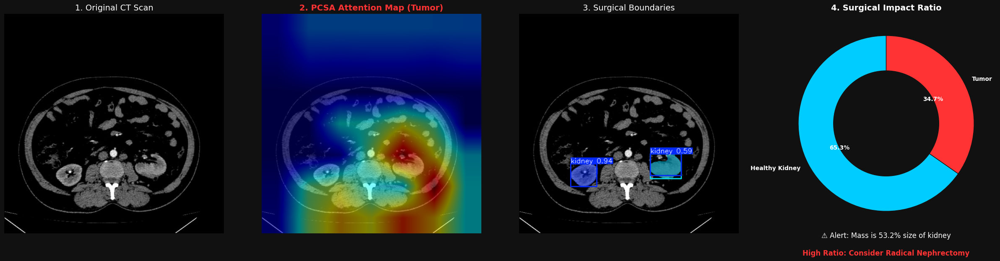

In [ ]:
# --- INSTALL DEPENDENCIES FIRST ---
!pip install -q grad-cam transformers

import torch
import cv2
from PIL import Image
from torchvision import transforms
import matplotlib.pyplot as plt
from ultralytics import YOLO
from transformers import pipeline
import glob
import random
import numpy as np

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import warnings
warnings.filterwarnings('ignore')

print("🏥 Initializing the AI Hospital Mainframe (Diagnostics & Dietitian)...")

# --- 1. LOAD NLP MEDICAL SCRIBE ---
nlp_ner = pipeline("ner", model="d4data/biomedical-ner-all", tokenizer="d4data/biomedical-ner-all", aggregation_strategy="simple")

patient_notes = """
Patient is a 55-year-old female presenting with hematuria and right-sided flank pain.
A CT scan of the abdomen revealed a 5cm solid, hypervascular mass on the right kidney, highly suspicious for Renal Cell Carcinoma (RCC).
Patient has a history of type 2 diabetes managed with Metformin.
Recommended radical nephrectomy due to the mass-to-kidney size ratio and risk of metastasis.
"""
extracted_entities = nlp_ner(patient_notes)

entity_dict = {}
for entity in extracted_entities:
    grp = entity['entity_group'].upper()
    raw_word = entity['word']
    clean_word = raw_word.replace("##", "").strip()

    if grp not in entity_dict:
        entity_dict[grp] = []

    if raw_word.startswith("##") and len(entity_dict[grp]) > 0:
        entity_dict[grp][-1] += clean_word
    else:
        entity_dict[grp].append(clean_word)

print("\n📋 PubMedBERT Extracted Clinical Context:")
for grp, words in entity_dict.items():
    unique_words = list(dict.fromkeys([w.title() for w in words]))
    combined_words = ", ".join(unique_words)
    print(f"   [{grp}] -> {combined_words}")
print("-" * 60)

hover_html = "<b>Patient Clinical Context:</b><br>"
for grp, words in entity_dict.items():
    unique_words = list(dict.fromkeys([w.title() for w in words]))
    combined_words = ", ".join(unique_words)
    hover_html += f"• <b>{grp}:</b> {combined_words}<br>"

# --- 1.5 THE AI CLINICAL DIETITIAN ---
print("\n🥗 AI Dietitian & Lifestyle Recommendations:")
dietary_plan = []

# Flatten all extracted words into one string to search for keywords
all_extracted_text = " ".join([" ".join(words) for words in entity_dict.values()]).upper()

if "DIABETES" in all_extracted_text or "METFORMIN" in all_extracted_text:
    dietary_plan.append("🩸 Diabetic-Renal Diet: Strict glycemic control. Prioritize complex carbs (low GI) to prevent kidney strain.")
if "HYPERTENSION" in all_extracted_text or "LISINOPRIL" in all_extracted_text:
    dietary_plan.append("🧂 DASH Diet: Restrict sodium intake to < 2000mg/day to manage blood pressure.")
if "CARCINOMA" in all_extracted_text or "TUMOR" in all_extracted_text or "RCC" in all_extracted_text:
    dietary_plan.append("🥩 Post-Nephrectomy Nutrition: High-quality, lean protein for tissue repair. Limit processed red meats.")
if "CYST" in all_extracted_text:
    dietary_plan.append("💧 Fluid Management: Maintain adequate hydration to flush the renal system.")
if "STONE" in all_extracted_text:
    dietary_plan.append("🍋 Stone Prevention: 2.5L-3L daily water intake. Limit high-oxalate foods. Moderate calcium.")

if not dietary_plan:
    dietary_plan.append("Balanced Renal Diet: Moderate protein, low sodium, and adequate hydration.")

for plan in dietary_plan:
    print(f"   {plan}")
print("-" * 60)

# Inject the diet plan into the 3D Hover Text
hover_html += "<br><b>Dietary & Lifestyle Plan:</b><br>"
for plan in dietary_plan:
    hover_html += f"• {plan}<br>"

# --- 1.5 THE DEEPSEEK AI CLINICAL DIETITIAN ---
from openai import OpenAI

print("\n🥗 Calling DeepSeek AI Dietitian...")

# Initialize the DeepSeek Client
client = OpenAI(
    api_key="sk-dfcad8122dc94d5a924f05d31a09f744", # <--- PUT YOUR DEEPSEEK API KEY HERE
    base_url="https://api.deepseek.com"
)

# We feed DeepSeek the raw patient notes so it understands the full context
diet_prompt = f"""
You are an expert clinical oncology dietitian. Review the following patient case:
'{patient_notes}'

Based on this specific patient's conditions (mass size, location, and medical history like diabetes or hypertension), provide exactly 3 concise bullet points for a post-operative dietary and lifestyle plan.
Keep it brief, professional, and directly applicable to their specific comorbidities. Do not use asterisks or markdown formatting.
"""

try:
    response = client.chat.completions.create(
        model="deepseek-chat",
        messages=[
            {"role": "system", "content": "You are a helpful medical AI assistant."},
            {"role": "user", "content": diet_prompt}
        ],
        max_tokens=150,
        temperature=0.3 # Low temperature for factual, medical responses
    )

    deepseek_output = response.choices[0].message.content.strip()

    # Split the output into a list of strings by looking for the bullet points or newlines
    dietary_plan = [line.strip() for line in deepseek_output.split('\n') if line.strip()]

    print("\n🥗 DeepSeek Personalized Care Plan:")
    for plan in dietary_plan:
        print(f"   {plan}")
    print("-" * 60)

except Exception as e:
    print(f"⚠️ DeepSeek API Error: {e}")
    dietary_plan = ["Balanced Renal Diet: Moderate protein, low sodium, and adequate hydration."]

# Inject the DeepSeek diet plan into the 3D Hover Text
hover_html += "<br><b>DeepSeek Dietary & Lifestyle Plan:</b><br>"
for plan in dietary_plan:
    hover_html += f"• {plan}<br>"

# --- 2. LOAD VISION MODELS ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pcsa_classifier.eval()

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

tumor_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt")
cyst_segmenter = YOLO("/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt")

# --- 3. EXECUTE INFERENCE ---
available_images = glob.glob('/content/datasets/*[Tt]umor*/test/images/*.jpg')
if len(available_images) == 0:
    print("❌ Error: Colab's temporary storage is empty.")
else:
    sample_scan = random.choice(available_images)
    print(f"\n🔬 Analyzing Scan: {sample_scan.split('/')[-1]}")
    print("-" * 60)

    img = Image.open(sample_scan).convert('RGB')
    input_tensor = transform(img).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = pcsa_classifier(input_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)[0]
        confidence, predicted_idx = torch.max(probabilities, 0)
        diagnosis = class_names[predicted_idx.item()]

    print(f"➡️ Stage 1 Diagnosis: {diagnosis} (Confidence: {confidence.item()*100:.2f}%)")

    # Grad-CAM
    target_layers = [pcsa_classifier.stage4]
    cam = GradCAM(model=pcsa_classifier, target_layers=target_layers)
    targets = [ClassifierOutputTarget(predicted_idx.item())]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0, :]
    grayscale_cam_resized = cv2.resize(grayscale_cam, (img.width, img.height))
    img_float = np.float32(img) / 255.0
    cam_image = show_cam_on_image(img_float, grayscale_cam_resized, use_rgb=True)

    # YOLO Routing
    yolo_results = None
    z_offset = 0
    title_color = '#00ccff'
    plot_color = '#00ccff'

    if diagnosis == "Tumor":
        yolo_results = tumor_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#ff3333', '#ff3333', 5
    elif diagnosis == "Cyst":
        yolo_results = cyst_segmenter.predict(source=sample_scan, conf=0.5, save=False, verbose=False)
        annotated_img = cv2.cvtColor(yolo_results[0].plot(), cv2.COLOR_BGR2RGB)
        title_color, plot_color, z_offset = '#00ff00', '#00ff00', 5
    else:
        annotated_img = np.array(img)

    # --- 4. CLINICAL SIZING MODULE ---
    kidney_total_area = 0.0
    pathology_total_area = 0.0
    pathology_name = diagnosis

    if yolo_results is not None and yolo_results[0].masks is not None:
        masks = yolo_results[0].masks.xy
        classes = yolo_results[0].boxes.cls
        names = yolo_results[0].names
        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]
            area = cv2.contourArea(mask.astype(np.float32))
            if name == 'kidney':
                kidney_total_area += area
            elif name in ['tumor', 'cyst']:
                pathology_total_area += area

    consumption_ratio = 0
    recommendation = "No significant mass detected."
    if kidney_total_area > 0 and pathology_total_area > 0:
        consumption_ratio = (pathology_total_area / kidney_total_area) * 100
        if consumption_ratio > 30.0:
            recommendation = "High Ratio: Consider Radical Nephrectomy"
        else:
            recommendation = "Moderate Ratio: Consider Partial Nephrectomy"

    # Inject the sizing data straight into the 3D NLP Hover Text
    hover_html += "<br><b>Automated Sizing Scribe:</b><br>"
    if pathology_total_area > 0:
        hover_html += f"• Mass Area: {pathology_total_area:,.0f} px²<br>"
        hover_html += f"• Severity Ratio: {consumption_ratio:.1f}%<br>"
        hover_html += f"• Protocol: {recommendation}<br>"

    # --- 5. 1x4 DASHBOARD PLOTTING ---
    fig, axes = plt.subplots(1, 4, figsize=(24, 6))
    fig.patch.set_facecolor('#111111')

    axes[0].imshow(img); axes[0].set_title("1. Original CT Scan", color='white', fontsize=14); axes[0].axis('off')
    axes[1].imshow(cam_image); axes[1].set_title(f"2. PCSA Attention Map ({diagnosis})", color=title_color, fontsize=14, weight='bold'); axes[1].axis('off')
    axes[2].imshow(annotated_img); axes[2].set_title("3. Surgical Boundaries", color='white', fontsize=14); axes[2].axis('off')

    # The New Donut Chart Visualization
    axes[3].set_title("4. Surgical Impact Ratio", color='white', fontsize=14, weight='bold')
    if pathology_total_area > 0:
        sizes = [kidney_total_area, pathology_total_area]
        labels = ['Healthy Kidney', pathology_name]
        colors = ['#00ccff', plot_color]

        wedges, texts, autotexts = axes[3].pie(
            sizes, labels=labels, colors=colors, autopct='%1.1f%%',
            startangle=90, textprops=dict(color="w", weight="bold"),
            wedgeprops=dict(width=0.4, edgecolor='#111111')
        )

        axes[3].text(0, -1.3, f"⚠️ Alert: Mass is {consumption_ratio:.1f}% size of kidney", color='white', ha='center', fontsize=12)
        axes[3].text(0, -1.5, recommendation, color=plot_color, ha='center', fontsize=12, weight='bold')
    else:
        axes[3].text(0.5, 0.5, "No Sizing Data Available", color='white', ha='center', va='center', fontsize=14)
        axes[3].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import plotly.graph_objects as go
import plotly.io as pio
import numpy as np

# Force Colab to render the Javascript widget
pio.renderers.default = 'colab'

# --- STAGE 3: 3D NLP GEOMETRY EXTRACTION ---
# This relies on the variables already generated in Cell 1!
if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    print(f"\n📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for {diagnosis}...")
    fig_3d = go.Figure()

    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    for i, mask in enumerate(masks):
        cls_id = int(classes[i].item())
        name = names[cls_id]
        x_coords, y_coords = mask[:, 0], mask[:, 1]

        if name in ['tumor', 'cyst']:
            z_coords = np.ones_like(x_coords) * z_offset
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color=plot_color),
                line=dict(color=plot_color, width=4),
                surfaceaxis=2, # <--- NEW: Fills the polygon to make it a solid object!
                surfacecolor=plot_color,
                opacity=0.85,  # Solid, highly visible pathology
                name=f"Extracted {name.capitalize()}",
                text=[hover_html] * len(x_coords), # INJECTING THE NLP TEXT!
                hoverinfo='text'
            ))
        else:
            z_coords = np.zeros_like(x_coords)
            fig_3d.add_trace(go.Scatter3d(
                x=x_coords, y=y_coords, z=z_coords,
                mode='lines+markers',
                marker=dict(size=2, color='#00ccff'),
                line=dict(color='#00ccff', width=4),
                surfaceaxis=2, # <--- NEW: Fills the healthy kidney!
                surfacecolor='#00ccff',
                opacity=0.3,   # <--- NEW: Makes the healthy tissue look like transparent glass
                name="Healthy Kidney",
                hoverinfo='none' # Keep the normal kidney clean
            ))

    # Dynamically inject the Surgical Sizing Recommendation into the 3D Title
    plot_title = f"<b>Interactive 3D Geometry with Embedded Medical NLP ({diagnosis})</b>"
    if 'recommendation' in locals():
        plot_title += f"<br><sup><i>Protocol: {recommendation}</i></sup>"

    fig_3d.update_layout(
        title=plot_title,
        scene=dict(
            xaxis_title="X-Axis", yaxis_title="Y-Axis", zaxis_title="Z-Axis",
            xaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            yaxis=dict(backgroundcolor="#111111", gridcolor="#333333"),
            zaxis=dict(backgroundcolor="#111111", gridcolor="#333333", range=[-10, 10]),
        ),
        paper_bgcolor="#111111", font=dict(color="white"), margin=dict(l=0, r=0, b=0, t=70)
    )
    print("✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:")
    fig_3d.show()

elif 'diagnosis' in locals() and diagnosis not in ["Tumor", "Cyst"]:
    print(f"✅ Diagnosis is {diagnosis}. No 3D surgical segmentation required.")
else:
    print("⚠️ Please run Cell 1 first so the AI can analyze an image!")


📐 Stage 3: Extracting Solid 3D Spatial Geometry with NLP Embedding for Tumor...
✅ 3D Geometry Extracted! Hover your mouse over the floating pathology below:


In [ ]:
import os

print("🧱 Initializing 3D Mesh Exporter...")

# The name of the file we are creating
obj_filename = "/content/Patient_Surgical_Meshnew.obj"

if 'yolo_results' in locals() and yolo_results is not None and yolo_results[0].masks is not None:
    masks = yolo_results[0].masks.xy
    classes = yolo_results[0].boxes.cls
    names = yolo_results[0].names

    vertex_offset = 1 # OBJ files start counting at 1, not 0

    with open(obj_filename, "w") as f:
        f.write("# Auto-generated Medical 3D Mesh by PCSA-KidneyNeXt Pipeline\n")
        f.write("o Surgical_Environment\n\n")

        for i, mask in enumerate(masks):
            cls_id = int(classes[i].item())
            name = names[cls_id]

            print(f"📐 Extruding 3D geometry for: {name.capitalize()}")
            f.write(f"g {name}_{i}\n")

            # Downscale the pixels so the mesh is a reasonable size
            scale = 0.02
            x_coords = mask[:, 0] * scale
            y_coords = mask[:, 1] * scale

            # Elevate the pathology so it pops out
            z_bottom = 0.0
            z_top = 1.5 if name in ['tumor', 'cyst'] else 0.5

            num_points = len(x_coords)

            # Write the Bottom Vertices (v)
            for x, y in zip(x_coords, y_coords):
                f.write(f"v {x:.4f} {y:.4f} {z_bottom:.4f}\n")

            # Write the Top Vertices (v)
            for x, y in zip(x_coords, y_coords):
                f.write(f"v {x:.4f} {y:.4f} {z_top:.4f}\n")

            # Write the Faces (f) to build the walls of the mesh
            for j in range(num_points):
                next_j = (j + 1) % num_points
                v1 = vertex_offset + j
                v2 = vertex_offset + next_j
                v3 = vertex_offset + num_points + next_j
                v4 = vertex_offset + num_points + j
                f.write(f"f {v1} {v2} {v3} {v4}\n")

            # Write the Top and Bottom "Cap" Faces
            bottom_face = " ".join([str(vertex_offset + j) for j in reversed(range(num_points))])
            top_face = " ".join([str(vertex_offset + num_points + j) for j in range(num_points)])

            f.write(f"f {bottom_face}\n")
            f.write(f"f {top_face}\n\n")

            # Update the global vertex count for the next organ
            vertex_offset += 2 * num_points

    print("-" * 50)
    print(f"✅ SUCCESS! 3D Mesh exported to: {obj_filename}")
    print("📥 You can now download it from the folder icon on the left side of Colab!")

else:
    print("⚠️ No YOLO Sizing Data found. Please run the Master Pipeline cell first.")

🧱 Initializing 3D Mesh Exporter...
📐 Extruding 3D geometry for: Kidney
📐 Extruding 3D geometry for: Kidney
📐 Extruding 3D geometry for: Tumor
--------------------------------------------------
✅ SUCCESS! 3D Mesh exported to: /content/Patient_Surgical_Meshnew.obj
📥 You can now download it from the folder icon on the left side of Colab!


In [ ]:
!pip install -q pydicom kagglehub openai grad-cam transformers ultralytics supervision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 85.0 MB/s eta 0:00:00


In [ ]:
# combining two datasets of roboflow

In [ ]:
# 1. Install dependencies
!pip install -q "ultralytics<=8.3.40" roboflow supervision pyyaml

import os
from roboflow import Roboflow

# Create staging directories
os.makedirs('/content/raw_tumor', exist_ok=True)
os.makedirs('/content/raw_cyst', exist_ok=True)

print("📥 Downloading Tumor Dataset...")
%cd /content/raw_tumor
rf = Roboflow(api_key="LYQUKUSB3DcOCIa4VAIW")
tumor_project = rf.workspace("capstone-6ikwu").project("kidney-tumor-uqpis-ytprj")
tumor_dataset = tumor_project.version(1).download("yolov11")

print("\n📥 Downloading Cyst Dataset...")
%cd /content/raw_cyst
cyst_project = rf.workspace("capstone-6ikwu").project("kidney-cyst-6ytvf-w7ogs")
cyst_dataset = cyst_project.version(1).download("yolov11")

print("\n✅ Both datasets downloaded to staging areas!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.9/41.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 898.5/898.5 kB 55.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.6/94.6 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 217.4/217.4 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 52.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 106.9 MB/s eta 0:00:00
📥 Downloading Tumor Dataset...
/content/raw_tumor
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Kidney-Tumor-1 in yolov11:: 100%|██████████| 4535/4535 [00:01<00:00, 4023.13it/s]


📥 Downloading Cyst Dataset...
/content/raw_cyst
loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to Kidney-Cyst-1 in yolov11:: 100%|██████████| 6175/6175 [00:01<00:00, 5148.53it/s]


✅ Both datasets downloaded to staging areas!


In [ ]:
import yaml
import shutil
import os

print("🧬 Initializing Smart Dataset Merger...")

# Define the paths
tumor_yaml_path = f"{tumor_dataset.location}/data.yaml"
cyst_yaml_path = f"{cyst_dataset.location}/data.yaml"
unified_dir = "/content/combined_dataset"

# Create the new unified directory structure
for split in ['train', 'valid', 'test']:
    os.makedirs(f"{unified_dir}/{split}/images", exist_ok=True)
    os.makedirs(f"{unified_dir}/{split}/labels", exist_ok=True)

# Define our new Master Class List
unified_classes = ['kidney', 'tumor', 'cyst']

def get_class_mapping(yaml_path):
    # Reads the dataset's yaml and figures out which old ID becomes which new ID
    with open(yaml_path, 'r') as f:
        data = yaml.safe_load(f)
    old_classes = data['names']

    mapping = {}
    for old_id, class_name in enumerate(old_classes):
        # Standardize names to lowercase to ensure they match
        clean_name = class_name.lower().strip()
        if clean_name in unified_classes:
            new_id = unified_classes.index(clean_name)
            mapping[old_id] = new_id
    return mapping

# Get the translation maps
tumor_map = get_class_mapping(tumor_yaml_path)
cyst_map = get_class_mapping(cyst_yaml_path)

def process_and_copy(src_base, mapping, prefix=""):
    # Copies images and rewrites the label files with the new IDs
    for split in ['train', 'valid', 'test']:
        img_dir = f"{src_base}/{split}/images"
        lbl_dir = f"{src_base}/{split}/labels"

        if not os.path.exists(img_dir): continue

        for filename in os.listdir(img_dir):
            # Copy Image with a prefix so filenames don't overwrite each other
            new_img_name = f"{prefix}_{filename}"
            shutil.copy(os.path.join(img_dir, filename), os.path.join(unified_dir, split, 'images', new_img_name))

            # Process Label
            lbl_name = filename.rsplit('.', 1)[0] + '.txt'
            new_lbl_name = f"{prefix}_{lbl_name}"
            src_lbl = os.path.join(lbl_dir, lbl_name)
            dest_lbl = os.path.join(unified_dir, split, 'labels', new_lbl_name)

            if os.path.exists(src_lbl):
                with open(src_lbl, 'r') as f_in, open(dest_lbl, 'w') as f_out:
                    for line in f_in:
                        parts = line.strip().split()
                        if not parts: continue
                        old_id = int(parts[0])
                        if old_id in mapping:
                            parts[0] = str(mapping[old_id])
                            f_out.write(" ".join(parts) + "\n")

print("🔄 Processing and mapping Tumor dataset...")
process_and_copy(tumor_dataset.location, tumor_map, prefix="tumor")

print("🔄 Processing and mapping Cyst dataset...")
process_and_copy(cyst_dataset.location, cyst_map, prefix="cyst")

# Create the Unified data.yaml file
unified_yaml_content = {
    'path': unified_dir,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'names': {i: name for i, name in enumerate(unified_classes)}
}

unified_yaml_path = f"{unified_dir}/data.yaml"
with open(unified_yaml_path, 'w') as f:
    yaml.dump(unified_yaml_content, f, default_flow_style=False)

print(f"✅ SUCCESS! Datasets successfully merged. Unified YAML saved to: {unified_yaml_path}")

🧬 Initializing Smart Dataset Merger...
🔄 Processing and mapping Tumor dataset...
🔄 Processing and mapping Cyst dataset...
✅ SUCCESS! Datasets successfully merged. Unified YAML saved to: /content/combined_dataset/data.yaml


In [ ]:
from ultralytics import YOLO

print("🔄 Initializing YOLOv11 Unified Segmentation Model...")
# Load the pre-trained YOLOv11 Nano Segmentation model
model = YOLO("yolo11n-seg.pt")

print("🚀 Starting Unified Training...")
# Train the model on the new combined dataset
results = model.train(
    data="/content/combined_dataset/data.yaml", # Pointing to our new smart-merged dataset
    epochs=50,
    imgsz=640,
    device=0,
    project="/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation",
    name="unified_segmentation_v1" # Saves as a brand new model
)

print("🎉 Unified Model Training Complete and Saved to Google Drive!")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
🔄 Initializing YOLOv11 Unified Segmentation Model...


100%|██████████| 5.90M/5.90M [00:00<00:00, 177MB/s]


🚀 Starting Unified Training...
New https://pypi.org/project/ultralytics/8.4.17 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=segment, mode=train, model=yolo11n-seg.pt, data=/content/combined_dataset/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation, name=unified_segmentation_v1, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, v

100%|██████████| 755k/755k [00:00<00:00, 133MB/s]


Overriding model.yaml nc=80 with nc=3

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  1     87040  ultralytics.nn.modules.block.C3k2            [128, 128, 1, True]           
  7                  -1  1    295424  ultralytics

100%|██████████| 5.35M/5.35M [00:00<00:00, 229MB/s]


... (153 outputs left out)

                   all        800       2341      0.916      0.879      0.946      0.706      0.917      0.879      0.942      0.657



50 epochs completed in 1.362 hours.
Optimizer stripped from /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/unified_segmentation_v1/weights/last.pt, 6.0MB
Optimizer stripped from /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/unified_segmentation_v1/weights/best.pt, 6.0MB

Validating /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/unified_segmentation_v1/weights/best.pt...
Ultralytics 8.3.40 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n-seg summary (fused): 265 layers, 2,835,153 parameters, 0 gradients, 9.6 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100%|██████████| 25/25 [00:13<00:00,  1.81it/s]


                   all        800       2341      0.915       0.88      0.946      0.706      0.917      0.879      0.942      0.657
                kidney        672       1103       0.95      0.942      0.982      0.818      0.952      0.943      0.968      0.677
                 tumor        338        417      0.877      0.871      0.947      0.745      0.876      0.868      0.943      0.744
                  cyst        461        821      0.919      0.826      0.909      0.553      0.925      0.827      0.915      0.549
Speed: 0.2ms preprocess, 3.5ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/unified_segmentation_v1
🎉 Unified Model Training Complete and Saved to Google Drive!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

print("⚖️ Initializing the Model Evaluation Protocol...")

# 1. Define the paths to your 3 trained models in Google Drive
tumor_weights = "/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt"
cyst_weights = "/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/cyst_segmentation_v1/weights/best.pt"
unified_weights = "/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/unified_segmentation_v1/weights/best.pt"

# 2. Set up our tracking dictionary
results_dict = {
    "Model Architecture": ["Tumor Specialist", "Cyst Specialist", "Unified Generalist"],
    "mAP50 (Overall Accuracy)": [],
    "Precision (Quality)": [],
    "Recall (Detection Rate)": []
}

# --- EVALUATE TUMOR SPECIALIST ---
print("\n📊 1/3: Evaluating Tumor Specialist Model...")
model_tumor = YOLO(tumor_weights)
# We test it against the raw tumor dataset
metrics_tumor = model_tumor.val(data=f"{tumor_dataset.location}/data.yaml", split='test', plots=False)
results_dict["mAP50 (Overall Accuracy)"].append(metrics_tumor.seg.map50)
results_dict["Precision (Quality)"].append(metrics_tumor.seg.mp)
results_dict["Recall (Detection Rate)"].append(metrics_tumor.seg.mr)

# --- EVALUATE CYST SPECIALIST ---
print("\n📊 2/3: Evaluating Cyst Specialist Model...")
model_cyst = YOLO(cyst_weights)
# We test it against the raw cyst dataset
metrics_cyst = model_cyst.val(data=f"{cyst_dataset.location}/data.yaml", split='test', plots=False)
results_dict["mAP50 (Overall Accuracy)"].append(metrics_cyst.seg.map50)
results_dict["Precision (Quality)"].append(metrics_cyst.seg.mp)
results_dict["Recall (Detection Rate)"].append(metrics_cyst.seg.mr)

# --- EVALUATE UNIFIED GENERALIST ---
print("\n📊 3/3: Evaluating Unified Generalist Model...")
model_unified = YOLO(unified_weights)
# We test it against the newly merged combined dataset
metrics_unified = model_unified.val(data="/content/combined_dataset/data.yaml", split='test', plots=False)
results_dict["mAP50 (Overall Accuracy)"].append(metrics_unified.seg.map50)
results_dict["Precision (Quality)"].append(metrics_unified.seg.mp)
results_dict["Recall (Detection Rate)"].append(metrics_unified.seg.mr)

print("\n" + "="*60)
print("✅ EVALUATION COMPLETE! GENERATING REPORT...")
print("="*60)

# --- VISUALIZATION & REPORTING ---
# 1. Print the Raw Data Table
df = pd.DataFrame(results_dict)
print("\n📋 Tabular Clinical Metrics:")
print(df.to_markdown(index=False, floatfmt=".3f"))

# 2. Plot the Comparison Bar Chart
# Set up a dark-themed plot to match your medical dashboard
plt.style.use('dark_background')
fig, ax = plt.subplots(figsize=(12, 7))

# Plot the bars
df.plot(x="Model Architecture",
        y=["mAP50 (Overall Accuracy)", "Precision (Quality)", "Recall (Detection Rate)"],
        kind="bar", ax=ax, color=['#00ccff', '#00ff00', '#ff3333'], width=0.6)

plt.title("AI Architecture Comparison: Specialists vs. Unified Generalist", fontsize=16, weight="bold", color='white', pad=20)
plt.ylabel("Performance Score (0.0 to 1.0)", fontsize=12, color='white')
plt.xlabel("")
plt.ylim(0, 1.1)
plt.xticks(rotation=0, fontsize=12, weight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=11, frameon=False)

# Add the exact numbers on top of each bar
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8),
                textcoords='offset points', color='white', weight='bold', fontsize=10)

plt.tight_layout()
plt.show()

⚖️ Initializing the Model Evaluation Protocol...

📊 1/3: Evaluating Tumor Specialist Model...


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Capstone_Kidney_Project/YOLO_Segmentation/tumor_segmentation_v1/weights/best.pt'